# Stability of boreal AGB and carbon from time-series: `boreal` and `ecoregions` summary CSV aggregation and analysis
#### previous notebook: `tile_stats` series for wide-area map uncertainties: `boreal` and `ecoregions`

*Update:*
+ new summary csv tiles are made during the `v3.1` run. 

*Old notes:*
+ in THEORY it's just the simple sum of squares equation  
`se_total = sqrt(sum(agbd_sd^2))`     
and for means:  
`se_mean = sqrt(sum(agbd_sd^2))/sqrt(n)`  
(n = number of pixels)  
+ are we sure that projecting the raster to 4326 doesnt alter `AGB` calcs? `AGB_pg = AGBD_mg_ha * 0.09 / 1e9` <-- but this only works if pixels are `0.09 ha` in size; and this changes in the reproject (pixels are now various sizes depending on latitude)

In [2]:
library(aws.s3)
library(tidyverse)
library(dplyr)

library(fs)
library(sf)
library(patchwork)

library(terra)

#library(raster)
library(viridis)

library(parallel)
library(stringr)

library(patchwork)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Linking to GEOS 3.12.1, GDAL 3.8.5, PROJ 9.4.0; sf_use_s2() is TRUE

terra 1.7.78


Attaching package: ‘terra’


The following object is masked from ‘package:patchwork’:

    area


The following object is masked from ‘package:tidyr’:

    extract


Loading required package: viridisLite



In [3]:
library(ggsci)

#### Figure export function

In [4]:
EXPORT_PNG_PDF <- function(m_plot_figure, OUT_FIGURE_DIR, DATA_NAME_STEM, VAR, EXPORT_TIME_STR=format(Sys.time(), "_%Y%m%d"), FIG_DIMS=c(8,16), TYPE='map'){
    
    for(OUT_TYPE in c('png', 'pdf')){
        
        map_fn = path(OUT_FIGURE_DIR, paste0(TYPE,"_",DATA_NAME_STEM,"_", VAR, EXPORT_TIME_STR,".", OUT_TYPE))
        print(map_fn)
        
        ggsave(plot = m_plot_figure,
               file = map_fn,
               device = OUT_TYPE, dpi = 300, width=FIG_DIMS[1], height=FIG_DIMS[2])
    }
}

## Get csv files in DPS output from Boreal Domain runs for 2016-2025

In [5]:
OUTDIR = '/projects/my-public-bucket/boreal_AGBD_trends'
OUT_FIGURE_DIR = path(OUTDIR, 'paper_figs')

In [6]:
source('/projects/code/maap_tools/notebooks/boreal_smry_functions.r')

Loading required package: sp


Attaching package: ‘raster’


The following object is masked from ‘package:dplyr’:

    select




In [7]:
source('/projects/code/maap_tools/notebooks/boreal_smry_functions.r')

In [8]:
Sys.setenv("AWS_DEFAULT_REGION" = "us-west-2") 

In [9]:
tile_realm_dict = create_simple_tile_realm_dict('/projects/shared-buckets/montesano/databank/boreal_tiles_v004_model_ready.gpkg', dict_name = "tile_realm_dict")

Reading tiles from: /projects/shared-buckets/montesano/databank/boreal_tiles_v004_model_ready.gpkg 
Transforming to WGS84 for coordinate calculation...
Calculating tile centroids...


Warning message:
“st_centroid assumes attributes are constant over geometries”



Realm assignment summary:

      Eurasia North America 
         3300          1656 


In [10]:
WWF_ECO_FN = '/projects/my-public-bucket/databank/wwf_terr_ecos.gpkg'
boreal_ecoid_name_dict = create_ecoregion_dictionary(WWF_ECO_FN, eco_num_col = 'ECO_ID', eco_name_col = 'ECO_NAME')

Reading ecoregions from: /projects/my-public-bucket/databank/wwf_terr_ecos.gpkg 
Successfully created ecoregion dictionary
Number of ecoregions: 827 
ECO_NUM range: -9999 to 81333 


In [11]:
boreal_ecoid_biome_dict = create_ecoregion_dictionary(WWF_ECO_FN, eco_num_col = 'ECO_ID', eco_name_col = 'BIOME')

Reading ecoregions from: /projects/my-public-bucket/databank/wwf_terr_ecos.gpkg 
Successfully created ecoregion dictionary
Number of ecoregions: 827 
ECO_NUM range: -9999 to 81333 


In [12]:
ecoregion_biome_dict # defined in boreal_smry_functions.r

1 
          "Tropical & Subtropical Moist Broadleaf Forests" 
                                                         2 
            "Tropical & Subtropical Dry Broadleaf Forests" 
                                                         3 
               "Tropical & Subtropical Coniferous Forests" 
                                                         4 
                     "Temperate Broadleaf & Mixed Forests" 
                                                         5 
                               "Temperate Conifer Forests" 
                                                         6 
                                    "Boreal Forests/Taiga" 
                                                         7 
"Tropical & Subtropical Grasslands, Savannas & Shrublands" 
                                                         8 
             "Temperate Grasslands, Savannas & Shrublands" 
                                                         9 
                           "Flooded Grasslands & Savannas" 
                                                        10 
                         "Montane Grasslands & Shrublands" 
                                                        11 
                                                  "Tundra" 
                                                        12 
                "Mediterranean Forests, Woodlands & Scrub" 
                                                        13 
                              "Deserts & Xeric Shrublands" 
                                                        14 
                                               "Mangroves"

## Process Boreal Domain Data for all years in parallel

#### Uses `process_year_data()` to find each boreal tile's `*boreal.csv` and `*boreal_eco.csv` (note: not all tiles have these)

In [12]:
years_to_process = c(2016, 2017, 2018, 2019, 2020, 2020, 2021, 2022, 2023, 2024, 2025)

release_versions = rep('v3.1.0', length(years_to_process))
identifiers = c('full_run_niter30_multiyear_atl08v6', 'full_run_niter30_multiyear_atl08v6', 'full_run_niter30_multiyear_atl08v6', 
                'full_run_niter30_multiyear_atl08v6', 'full_run_niter30_multiyear_atl08v6', 'full_run',
                'full_run_niter30_multiyear_atl08v6', 'full_run_niter30_multiyear_atl08v6', 'full_run_niter30_multiyear_atl08v6',
                'full_run_niter30_multiyear_atl08v6', 'full_run_niter30_multiyear_atl08v6'
               )

results = process_boreal_data_parallel(
    years_list = years_to_process,
    RELEASE_VERSION_LIST = release_versions,
    IDENTIFIER_LIST = identifiers,
    n_cores = 11
)

# Extract results
boreal_all_years_df = results$boreal
boreal_eco_all_years_df = results$boreal_eco

#### Save these intermediate files

In [214]:
write.csv(boreal_all_years_df, path(OUTDIR,'tables', 'boreal_all_years_df.csv'), row.names = FALSE)
write.csv(boreal_eco_all_years_df, path(OUTDIR,'tables', 'boreal_eco_all_years_df.csv'), row.names = FALSE)

### Read back in, clean data frames, create summaries, and save final data frames

In [59]:
boreal_all_years_df = read.csv(path(OUTDIR,'tables', 'boreal_all_years_df.csv'))
boreal_eco_all_years_df = read.csv(path(OUTDIR,'tables', 'boreal_eco_all_years_df.csv'))

#### These are tile-level data frames

+ basic cleaning: remove the iter=250 for 2020 

In [60]:
# Remove iter=-1 rows and prepare data
boreal_clean <- boreal_all_years_df %>%
            filter(iter != -1) %>% # <-- this -1 iteration represents the mean total Pg of all the iterations
            mutate(IDENTIFIER = recode_factor(factor(IDENTIFIER), 'full_run_niter30_multiyear_atl08v6' = 'multi-year\nn iter=30', 'full_run' = 'single-year\nn iter=250')) %>%
            mutate(realm = tile_realm_dict[as.character(tile_num)]) %>% # North America , Eurasia
            filter(IDENTIFIER == 'multi-year\nn iter=30') %>%
            droplevels()

boreal_eco_clean <- boreal_eco_all_years_df %>%
            filter(iter != -1)  %>% # <-- this -1 iteration represents the mean total Pg of all the iterations
            mutate(IDENTIFIER = recode_factor(factor(IDENTIFIER), 'full_run_niter30_multiyear_atl08v6' = 'multi-year\nn iter=30', 'full_run' = 'single-year\nn iter=250')) %>%
            mutate(realm = tile_realm_dict[as.character(tile_num)]) %>% # North America , Eurasia
            mutate(eco_name = factor(
            ifelse(
              as.character(boreal_eco) %in% names(boreal_ecoid_name_dict),
              boreal_ecoid_name_dict[as.character(boreal_eco)],
              paste0("Ecoregion ", boreal_eco)  # Fallback for unknown codes
            ))) %>%
            mutate(biome_id = factor(
            ifelse(
              as.character(boreal_eco) %in% names(boreal_ecoid_biome_dict),
              boreal_ecoid_biome_dict[as.character(boreal_eco)],
              paste0("Biome ", boreal_eco)  # Fallback for unknown codes
            ))) %>%
            mutate(biome_name = factor(
            ifelse(
              as.character(biome_id) %in% names(ecoregion_biome_dict),
              ecoregion_biome_dict[as.character(biome_id)],
              paste0("Biome ", biome_id)  # Fallback for unknown codes
            ))) %>% 
            filter(IDENTIFIER == 'multi-year\nn iter=30') %>%
            droplevels()


In [61]:
head(boreal_all_years_df)

,boreal,AGB_Pg,count,iter,tile_num,TYPE,year,RELEASE_VERSION,IDENTIFIER,year_index
,<int>,<dbl>,<int>,<int>,<int>,<chr>,<int>,<chr>,<chr>,<int>
1,1,0.01095874,7048547,1,1857,boreal,2016,v3.1.0,full_run_niter30_multiyear_atl08v6,1
2,1,0.01043960,7048547,2,1857,boreal,2016,v3.1.0,full_run_niter30_multiyear_atl08v6,1
3,1,0.01058637,7048547,3,1857,boreal,2016,v3.1.0,full_run_niter30_multiyear_atl08v6,1
4,1,0.01073392,7048547,4,1857,boreal,2016,v3.1.0,full_run_niter30_multiyear_atl08v6,1
5,1,0.01088194,7048547,5,1857,boreal,2016,v3.1.0,full_run_niter30_multiyear_atl08v6,1
6,1,0.01068598,7048547,6,1857,boreal,2016,v3.1.0,full_run_niter30_multiyear_atl08v6,1


### Example: the `boreal_eco.csv` has each `tiles` set of pixels for a given `ecoregion`

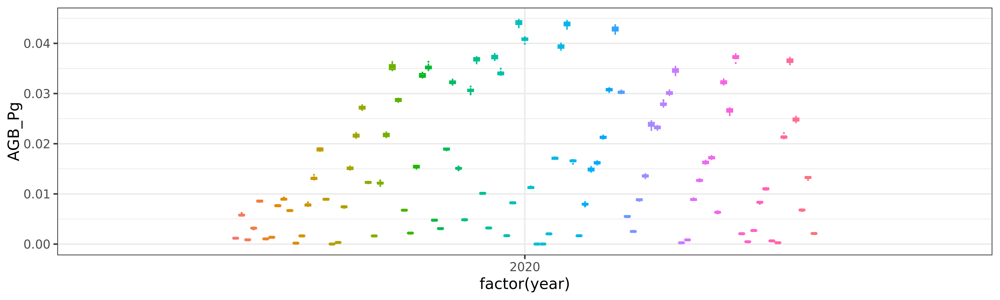

In [33]:
options(repr.plot.width = 10, repr.plot.height = 3, repr.plot.res = 300)
ggplot(boreal_eco_clean %>% filter(eco_name == 'Central Canadian Shield forests') %>% filter(year == 2020), aes(x=factor(year), y=AGB_Pg, color=factor(tile_num))) + geom_boxplot(outlier.size=FALSE) + theme_bw() + theme(legend.position = "none")

### Example: beyond the `tile` domain, we summarize by `boreal` and `ecoregion` domains 

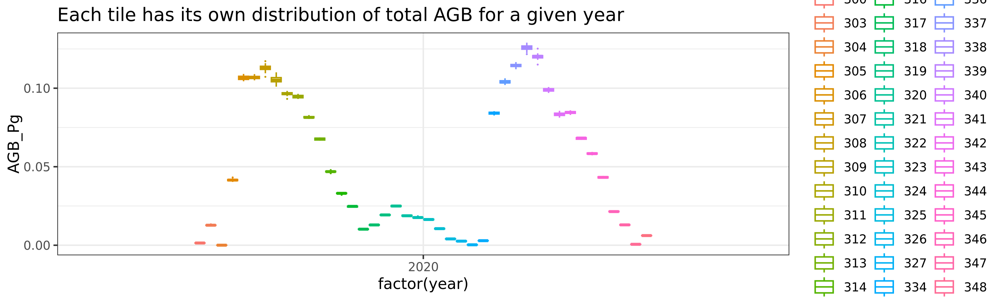

In [34]:
options(repr.plot.width = 10, repr.plot.height = 3, repr.plot.res = 300)
ggplot(boreal_clean %>% filter(tile_num >= 300 & tile_num < 350) %>% filter(year == 2020), aes(x=factor(year), y=AGB_Pg, color=factor(tile_num))) + geom_boxplot(outlier.size=FALSE) + theme_bw() + labs(title='Each tile has its own distribution of total AGB for a given year') #+ theme(legend.position = "none")

### Example: this means that border `tiles` will be associated with multiple `ecoregions` and summed according to the pixels masked by those ecoregions

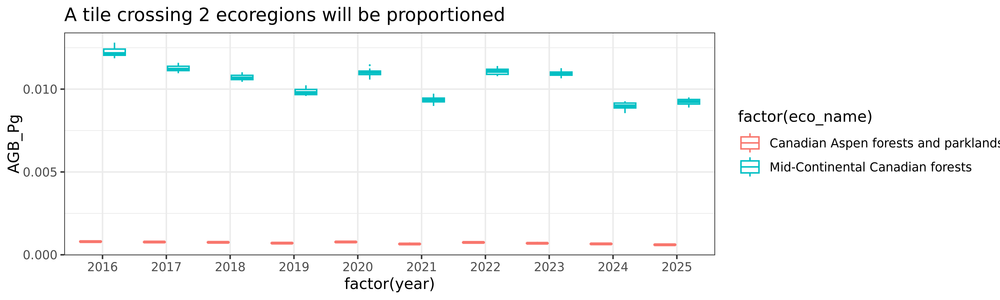

In [35]:
options(repr.plot.width = 10, repr.plot.height = 3, repr.plot.res = 300)
ggplot(boreal_eco_clean %>% filter(tile_num == 2371 ), aes(x=factor(year), y=AGB_Pg, color=factor(eco_name))) + geom_boxplot(outlier.size=FALSE) + theme_bw() + labs(title='A tile crossing 2 ecoregions will be proportioned') #+ theme(legend.position = "none")

## Create the summary files sum across various domains

In [62]:
source('/projects/code/maap_tools/notebooks/boreal_smry_functions.r')

In [63]:
boreal_summary = create_boreal_summary_correct(boreal_clean, group_by_cols = c("year", "tile_num", "RELEASE_VERSION", "IDENTIFIER"))

In [64]:
boreal_summary_realm  = create_boreal_summary_correct(boreal_clean, group_by_cols = c("year", "tile_num", "RELEASE_VERSION", "IDENTIFIER", "realm"), spatial_subdivisions = c("realm"))

In [65]:
boreal_summary_biome <- create_boreal_summary_correct(boreal_eco_clean, group_by_cols = c("year", "tile_num", "RELEASE_VERSION", "IDENTIFIER", "realm", "biome_name"), spatial_subdivisions = c("realm", "biome_name")) %>%
            mutate(across(c(biome_name), 
                        ~str_replace_all(., c("Mountains" = "Mtns", "Mountain" = "Mtn", "montane" = "mtn", "hemiboreal" = 'hemibor.',
                                             " and " = " & "))))# %>%
            #filter(!(biome_name %in% c('Biome 98', 'Montane Grasslands & Shrublands', 'Deserts & Xeric Shrublands')))

In [66]:
boreal_summary_ecoregion <- create_boreal_summary_correct(boreal_eco_clean, group_by_cols = c("year", "tile_num", "RELEASE_VERSION", "IDENTIFIER", "realm", "biome_name", 'eco_name'), spatial_subdivisions = c("realm", "biome_name", 'eco_name')) %>%
            mutate(across(c(biome_name, eco_name), 
                        ~str_replace_all(., c("Mountains" = "Mtns", "Mountain" = "Mtn", "montane" = "mtn", "hemiboreal" = 'hemibor.',
                                             " and " = " & ")))) #%>%
            #filter(!(biome_name %in% c('Biome 98', 'Montane Grasslands & Shrublands', 'Deserts & Xeric Shrublands')))

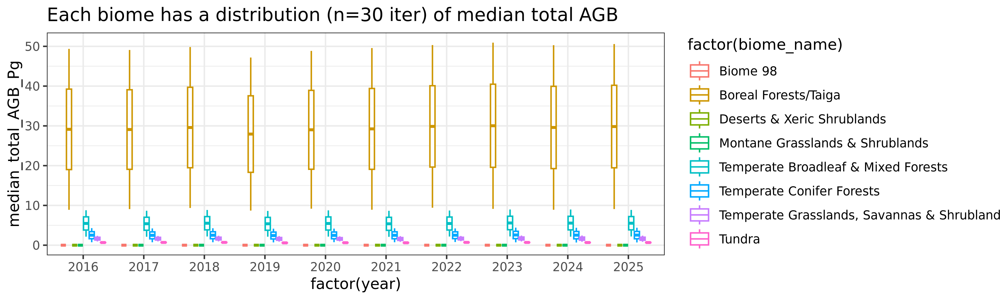

In [41]:
options(repr.plot.width = 10, repr.plot.height = 3, repr.plot.res = 300)
ggplot(boreal_summary_biome, aes(x=factor(year), y=median_total_AGB_Pg, color=factor(biome_name))) + geom_boxplot(outlier.size=FALSE) + theme_bw() + labs(title='Each biome has a distribution (n=30 iter) of median total AGB') #+ theme(legend.position = "none")

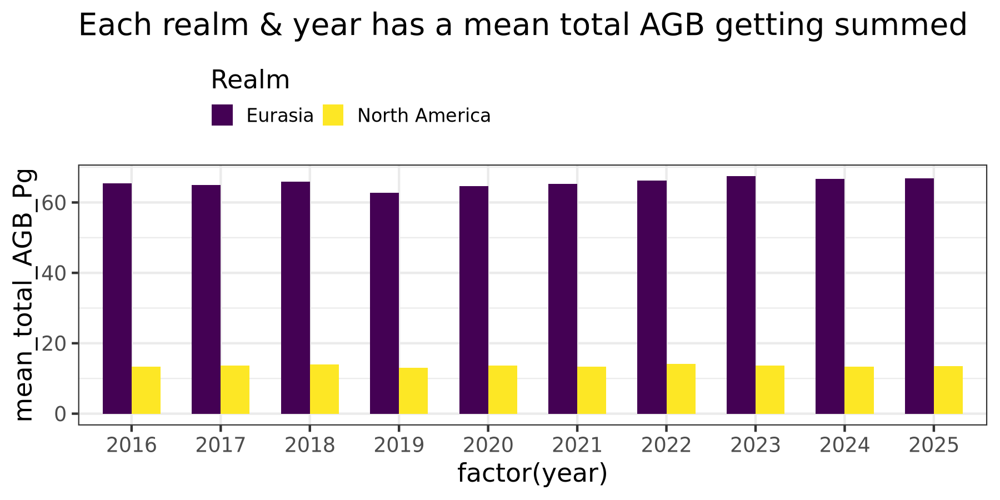

In [42]:
options(repr.plot.width = 6, repr.plot.height = 3, repr.plot.res = 300)

ggplot(boreal_summary_realm %>% filter(IDENTIFIER == 'multi-year\nn iter=30') , aes(x=factor(year), y=mean_total_AGB_Pg, fill=factor(realm))) + geom_col(alpha = 1, width = 0.65
                   , position='dodge') + scale_fill_viridis_d(name='Realm') + theme_bw() + labs(title='Each realm & year has a mean total AGB getting summed') + theme(legend.position = "top", legend.text=element_text(size=8)) + guides(
              fill = guide_legend(
                ncol = 20, 
                byrow = TRUE,
                title.position = "top",
                label.position = "right",
                keywidth = unit(0.25, "lines"),      # Width of the color box
                keyheight = unit(0.5, "lines"),       # Height of the color box
                override.aes = list(size = 3)       # Size of legend points/keys
              ))

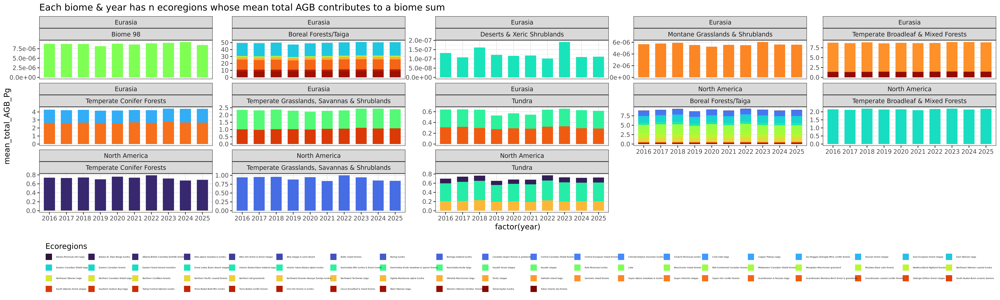

In [43]:
options(repr.plot.width = 20, repr.plot.height = 6, repr.plot.res = 300)
library(viridis)
# Or turbo (great for many categories)
colors_71 <- viridis(71, option = "turbo")
ggplot(boreal_summary_ecoregion %>% filter(IDENTIFIER == 'multi-year\nn iter=30') #%>% filter(!(biome_name %in% c('Biome 98', 'Montane Grasslands & Shrublands', 'Deserts & Xeric Shrublands')))
       , aes(x=factor(year), y=mean_total_AGB_Pg, fill=factor(eco_name))) + geom_col(alpha = 1, width = 0.65
                   , position='stack') + scale_fill_manual(values = colors_71, name='Ecoregions') + theme_bw() + labs(title='Each biome & year has n ecoregions whose mean total AGB contributes to a biome sum') + facet_wrap(realm~biome_name, scales='free_y', ncol=5) + theme(legend.position = "bottom", legend.text=element_text(size=3)) + guides(
              fill = guide_legend(
                ncol = 20, 
                byrow = TRUE,
                title.position = "top",
                label.position = "right",
                keywidth = unit(0.25, "lines"),      # Width of the color box
                keyheight = unit(0.5, "lines"),       # Height of the color box
                override.aes = list(size = 3)       # Size of legend points/keys
              ))

In [44]:
dim(boreal_summary_biome %>% filter(year == 2016))

[1] 13 20

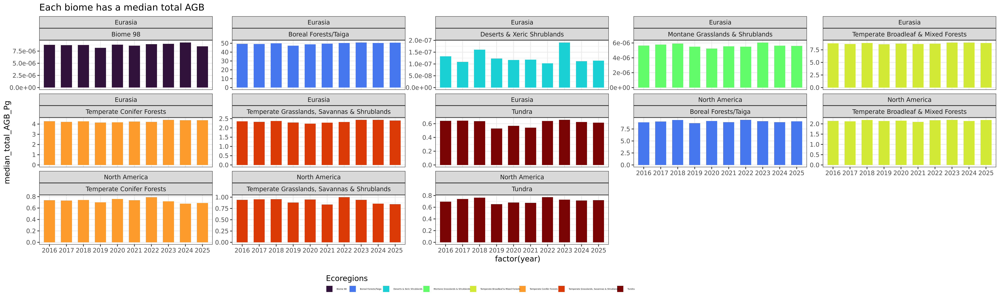

In [45]:
ggplot(boreal_summary_biome %>% filter(IDENTIFIER == 'multi-year\nn iter=30') #%>% filter(!(biome_name %in% c('Biome 98', 'Montane Grasslands & Shrublands', 'Deserts & Xeric Shrublands')))
       , aes(x=factor(year), y=median_total_AGB_Pg, fill=factor(biome_name))) + geom_col(alpha = 1, width = 0.65
                   , position='stack') + scale_fill_viridis_d(option = 'turbo', name='Ecoregions') + theme_bw() + labs(title='Each biome has a median total AGB') + facet_wrap(realm~biome_name, scales='free_y', ncol=5) + theme(legend.position = "bottom", legend.text=element_text(size=3)) + guides(
              fill = guide_legend(
                ncol = 20, 
                byrow = TRUE,
                title.position = "top",
                label.position = "right",
                keywidth = unit(0.25, "lines"),      # Width of the color box
                keyheight = unit(0.5, "lines"),       # Height of the color box
                override.aes = list(size = 3)       # Size of legend points/keys
              ))

### Save tables

In [13]:
library(fs)

In [14]:
OUTDIR = '/projects/my-public-bucket/boreal_AGBD_trends'
OUT_FIGURE_DIR = path(OUTDIR, 'paper_figs')

In [658]:
write.csv(boreal_summary, path(OUTDIR,'tables', 'boreal_summary.csv'), row.names = FALSE)
write.csv(boreal_summary_realm, path(OUTDIR,'tables', 'boreal_summary_realm.csv'), row.names = FALSE)
write.csv(boreal_summary_biome, path(OUTDIR,'tables', 'boreal_summary_biome.csv'), row.names = FALSE)
write.csv(boreal_summary_ecoregion, path(OUTDIR,'tables', 'boreal_summary_ecoregion.csv'), row.names = FALSE)

In [567]:
#write.csv(boreal_eco_year_stats, path(OUTDIR,'tables', 'boreal_eco_year_stats.csv'), row.names = FALSE)
#write.csv(boreal_eco_year_stats_realm, path(OUTDIR,'tables', 'boreal_eco_year_stats_realm.csv'), row.names = FALSE)
#write.csv(boreal_eco_year_stats_realm_biome, path(OUTDIR,'tables', 'boreal_eco_year_stats_realm_biome.csv'), row.names = FALSE)

### Read back in

In [12]:
boreal_summary = read.csv(path(OUTDIR,'tables', 'boreal_summary.csv'))
boreal_summary_realm = read.csv(path(OUTDIR,'tables', 'boreal_summary_realm.csv'))
boreal_summary_biome = read.csv(path(OUTDIR,'tables', 'boreal_summary_biome.csv'))
boreal_summary_ecoregion = read.csv(path(OUTDIR,'tables', 'boreal_summary_ecoregion.csv'))

# Figures

In [13]:
DIR_MAIN = '/projects/my-public-bucket/boreal_AGBD_trends'
dir.create(DIR_MAIN)
OUT_FIGURE_DIR = paste0(DIR_MAIN,'/paper_figs')
dir.create(OUT_FIGURE_DIR)

Warning message in dir.create(DIR_MAIN):
“'/projects/my-public-bucket/boreal_AGBD_trends' already exists”
Warning message in dir.create(OUT_FIGURE_DIR):
“'/projects/my-public-bucket/boreal_AGBD_trends/paper_figs' already exists”


#### Bar plot time series

In [14]:
# Create a more informative stacked bar plot with ecoregion names

do_time_series_AGB <- function(boreal_summary, DO_CARBON=FALSE, DO_LABELS=FALSE){
        scale_factor = 1
        VAR_NAME='biomass'
        if(DO_CARBON){
            scale_factor=0.5
            VAR_NAME='carbon'
        }
    
        boreal_summary$domain = 'Circumpolar domain'
        plot_boreal_year_named <- ggplot(boreal_summary, 
                                        aes(x = factor(year), y = mean_total_AGB_Pg * scale_factor, fill=factor(IDENTIFIER))) +
            geom_col(alpha = 1, width = 0.65
                   , position=position_dodge(width = 0.75)
                  ) +
            # min & max
            geom_errorbar( 
                aes(ymin = min_total_AGB_Pg * scale_factor, 
                    ymax = max_total_AGB_Pg * scale_factor
                    , group=factor(IDENTIFIER)
                    ), 
                width = 0.35, size = 0.5, color = "#253494" 
                , position=position_dodge(width = 0.5)
                    )+
            # SD
            geom_errorbar(
                aes(
                  x = factor(year), 
                  y = mean_total_AGB_Pg * scale_factor,
                  ymin = mean_total_AGB_Pg * scale_factor - sd_total_AGB_Pg * scale_factor, 
                  ymax = mean_total_AGB_Pg * scale_factor + sd_total_AGB_Pg * scale_factor
                  , group=factor(IDENTIFIER)
                  ),
                width = 0.25, size = 0.75, color = '#2c7fb8'
                , position=position_dodge(width = 0.5)
            ) +
            # SE
            geom_errorbar(
                aes(
                  x = factor(year), 
                  y = mean_total_AGB_Pg * scale_factor,
                  ymin = mean_total_AGB_Pg * scale_factor - se_total_AGB_Pg * scale_factor, 
                  ymax = mean_total_AGB_Pg * scale_factor + se_total_AGB_Pg * scale_factor
                  , group=factor(IDENTIFIER)
                ),
                width = 0.15, size = 1.0, color = "#41b6c4" 
                , position=position_dodge(width = 0.5)
            ) +
    
            #scale_fill_viridis_d(name =  "ICESat-2 / HLS model type", option = "viridis") +
            #scale_fill_brewer(palette='Dark2', name =  "ICESat-2 / HLS model type") +
            scale_fill_manual(values = c('gray70'), name =  "ICESat-2 / HLS model type")+
    
            # scale_fill_jco()+
            # scale_fill_tron()+
            # scale_fill_npg()+
            #scale_fill_jco(name = "ICESat-2 / HLS model type")+
            labs(
                x = "Year",
                y = paste0("Aboveground ",VAR_NAME," [Pg]")
            ) +
            theme_bw() +
            theme(
                plot.title = element_text(size = 14, face = "bold"),
                plot.subtitle = element_text(size = 10, color = "gray60"),
                axis.title = element_text(size = 12),
                axis.text = element_text(size = 12),
                axis.text.x = element_text(angle = 45, vjust=0.5),
                legend.position = "bottom",
                legend.title = element_text(size = 10, face = "bold"),
                panel.grid.minor = element_blank(),
                legend.text = element_text(size = 8)
            ) +
            scale_y_continuous(expand = expansion(mult = c(0, 0.15))) +
            guides(fill = guide_legend(ncol = 8, title.position = "top")) 

    geom_list_labels = list(
                ###
                # Error Labels 
                geom_label(
                    data = boreal_summary,
                    aes(
                      x = factor(year), 
                     # Just label positioning here...
                      y = mean_total_AGB_Pg * scale_factor - 0.5 * (mean_total_AGB_Pg * scale_factor), #total_mean_AGB_Pg + total_se_AGB_Pg + max(total_mean_AGB_Pg) * 0.05,
                      label = paste0("", round(mean_total_AGB_Pg * scale_factor, 3),
                                     " \n", 
                                     "±\n", 
                                     ## Using SD for label
                                     #round(sd_total_AGB_Pg * scale_factor, 3) 
                                     
                                     # Using +/- is half of the range for label - this corresponds with the min/max error bars shown
                                     round(0.5 * (max_total_AGB_Pg * scale_factor - min_total_AGB_Pg * scale_factor), 3) 
                                   )
                    , group=factor(IDENTIFIER)
                    ),
                    position=position_dodge(width = 0.5),
                    size = 2,
                    fill = "white",
                    alpha = 0.85,
                    label.padding = unit(0.2, "lines"),
                    inherit.aes = FALSE
                ),
                geom_label(
                    data = boreal_summary,
                    aes(
                      x = factor(year), 
                        y=0,
                        label = paste0(n_tiles,  "\ntiles")
                    , group=factor(IDENTIFIER)
                    ),
                    position=position_dodge(width = 0.5),
                    size = 2.0, angle=0, vjust=0,
                    fill = "white",
                    alpha = 0.85,
                    label.padding = unit(0.2, "lines"),
                    inherit.aes = FALSE
                )
        )

    if(DO_LABELS){plot_boreal_year_named = plot_boreal_year_named + geom_list_labels}
    
    return(plot_boreal_year_named)
}

# General function to reorder factor levels by a summary statistic
reorder_facets_by_column <- function(df, facet_var, sort_var, 
                                     fun = sum, decreasing = TRUE) {
  # Calculate summary statistic for each facet level
  summary_df <- df %>%
    group_by(across(all_of(facet_var))) %>%
    summarise(sort_value = fun(!!sym(sort_var), na.rm = TRUE), .groups = "drop") %>%
    arrange(if(decreasing) desc(sort_value) else sort_value)
  
  # Reorder the factor
  df[[facet_var]] <- factor(df[[facet_var]], 
                            levels = summary_df[[facet_var]])
  
  return(df)
}

#### Check - sums of `min_total_AGB_Pg` should be consistent across various summary files for same areas

cant do `Biome` levels error bars - just `boreal` or `ecoregion`?

In [15]:
sum((boreal_summary %>% filter(year == 2025))$min_total_AGB_Pg)

[1] 77.90398

In [16]:
sum((boreal_summary_realm %>% filter(year == 2025))$min_total_AGB_Pg)

[1] 77.90398

In [17]:
sum((boreal_summary_biome %>% filter(year == 2025))$min_total_AGB_Pg)

[1] 77.89471

In [21]:
sum((boreal_summary_ecoregion %>% filter(year == 2025))$min_total_AGB_Pg)

[1] 77.89471

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


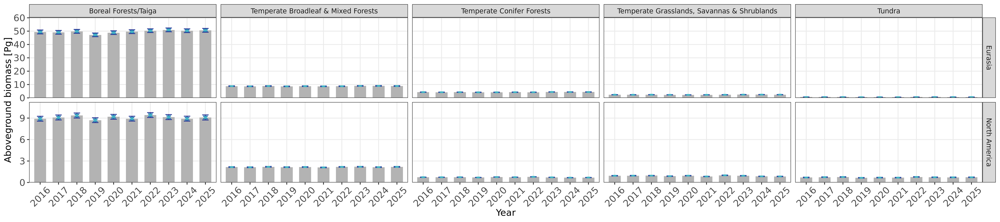

In [22]:
options(repr.plot.width = 18, repr.plot.height = 4, repr.plot.res = 300)

p_bars_boreal_biomes = do_time_series_AGB(
    reorder_facets_by_column(
                    boreal_summary_biome %>% filter(!(biome_name %in% c('Biome 98', 'Montane Grasslands & Shrublands', 'Deserts & Xeric Shrublands')))
                    , 'biome_name', 'mean_total_AGB_Pg')
                   , DO_CARBON=FALSE, DO_LABELS=FALSE)  + theme(legend.position = "none") + 
   facet_grid(realm~biome_name,
              scales = "free_y" #, space = "free"
             )  # Only works with facet_grid
p_bars_boreal_biomes

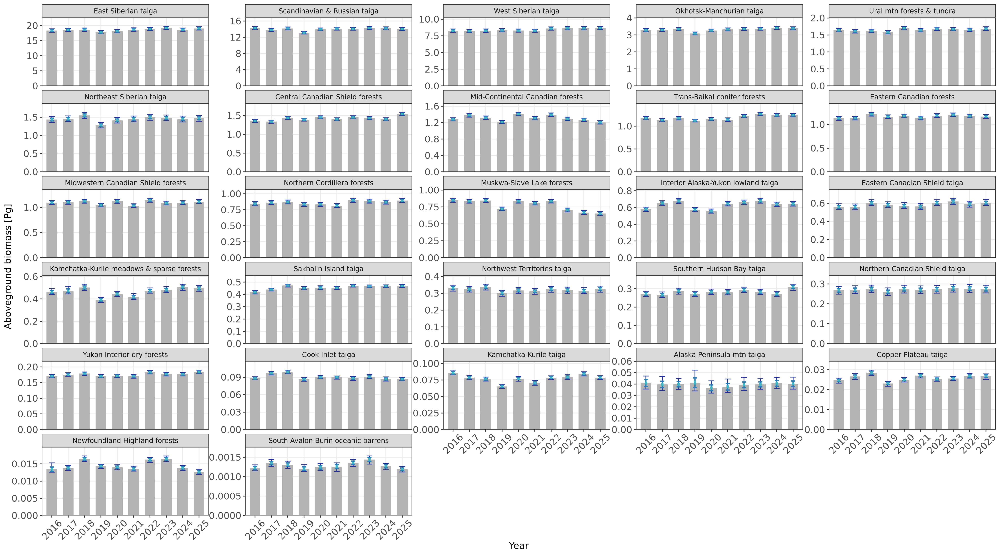

In [72]:
options(repr.plot.width = 18, repr.plot.height = 10, repr.plot.res = 300)

p_bars_boreal_ecoregions = do_time_series_AGB(
    reorder_facets_by_column(
                    boreal_summary_ecoregion %>% filter(biome_name == 'Boreal Forests/Taiga')
                    , 'eco_name', 'mean_total_AGB_Pg')
                   , DO_CARBON=FALSE, DO_LABELS=FALSE)  + theme(legend.position = "none") + 
   facet_wrap(~factor(eco_name), ncol=5, scales='free_y') 
p_bars_boreal_ecoregions

# Total aboveground carbon and uncertainty: time series 

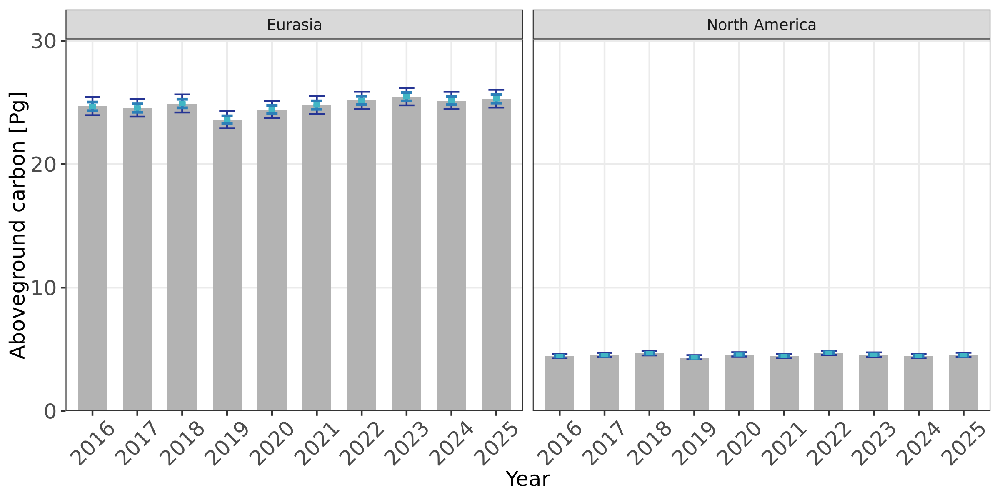

In [43]:
options(repr.plot.width = 8, repr.plot.height = 4, repr.plot.res = 300)

p_bars_realm = do_time_series_AGB(boreal_summary_biome %>% filter(biome_name == 'Boreal Forests/Taiga')
                   , DO_CARBON=TRUE, DO_LABELS=FALSE)  + theme(legend.position = "none") + 
   facet_wrap(~factor(realm), ncol=2) #+ coord_cartesian(ylim=c(70*0.5,83*0.5))
p_bars_realm

In [44]:
EXPORT_PNG_PDF(p_bars_realm, OUT_FIGURE_DIR, 'bars_realm', '2016-2025', FIG_DIMS=c(6,3), TYPE='plot')

/projects/my-public-bucket/boreal_AGBD_trends/paper_figs/plot_bars_realm_2016-2025_20260424.png
/projects/my-public-bucket/boreal_AGBD_trends/paper_figs/plot_bars_realm_2016-2025_20260424.pdf


## TODO: fix --> `circumpolar boreal` should be just biome=8; `circumpolar domain` can be biome=8 + transitional regions

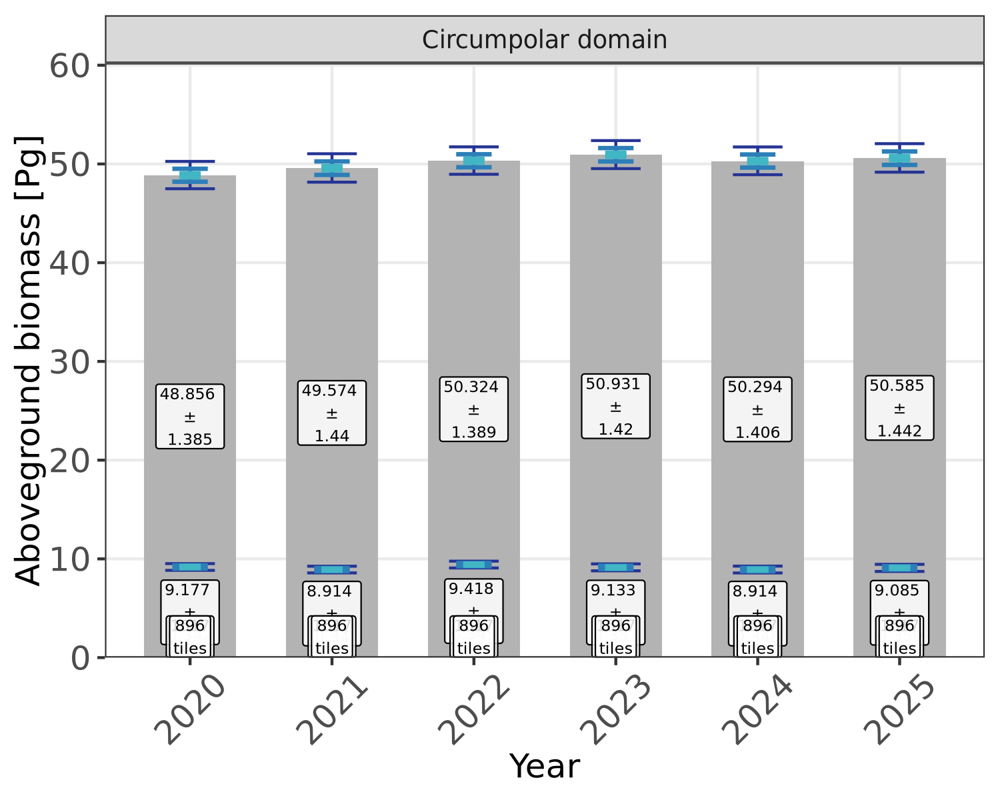

In [45]:
options(repr.plot.width = 5, repr.plot.height = 4, repr.plot.res = 300)

do_time_series_AGB(boreal_summary_biome %>% filter(biome_name == 'Boreal Forests/Taiga') %>%
                   filter(year > 2019)
                   , DO_CARBON=FALSE, DO_LABELS=TRUE)   + theme(legend.position = "none") + 
   facet_wrap(~factor(domain), ncol=1, scales='free') #+ coord_cartesian(ylim=c(70*0.5,83*0.5))

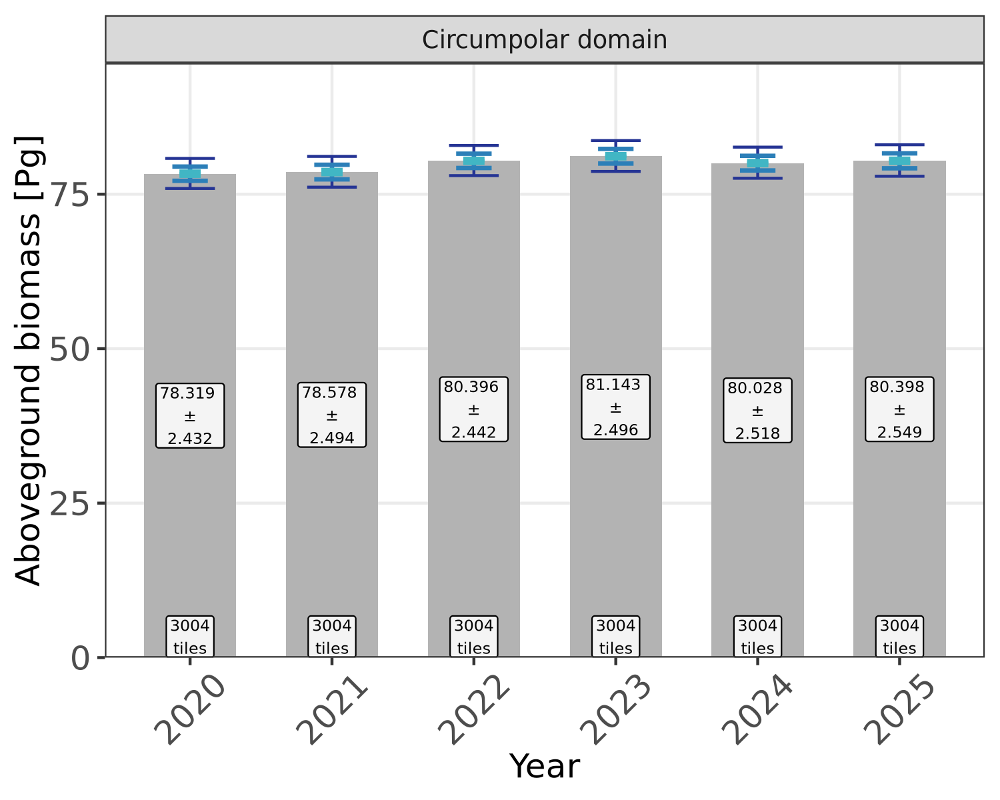

In [46]:
options(repr.plot.width = 5, repr.plot.height = 4, repr.plot.res = 300)

do_time_series_AGB(boreal_summary %>% 
                   filter(year > 2019)
                   , DO_CARBON=FALSE, DO_LABELS=TRUE)   + theme(legend.position = "none") + 
   facet_wrap(~factor(domain), ncol=1, scales='free') #+ coord_cartesian(ylim=c(70*0.5,83*0.5))

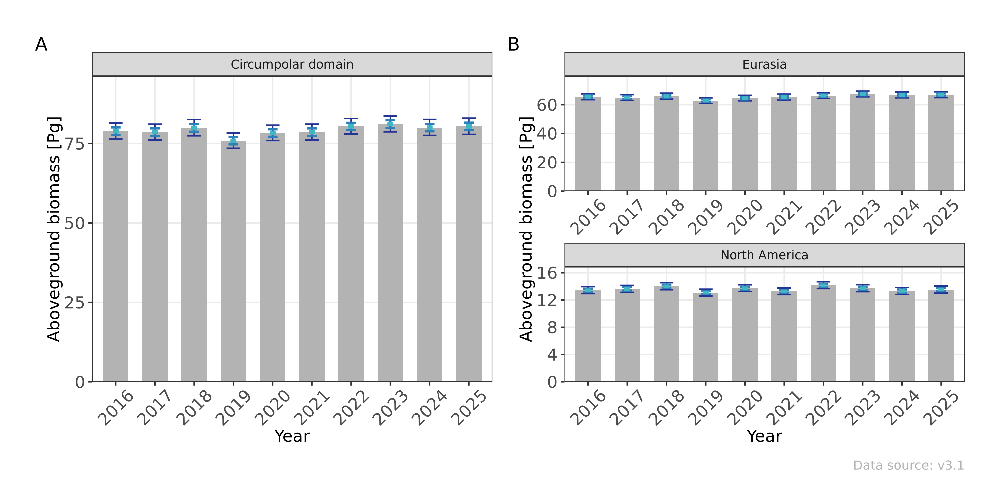

In [47]:
options(repr.plot.width = 10, repr.plot.height = 5, repr.plot.res = 300)

design <- "
  111222
  111222
"

( (do_time_series_AGB(boreal_summary , DO_CARBON=FALSE)  + facet_wrap(~factor(domain), ncol=1, scales='free') + theme(legend.position = "none")) / 
  (do_time_series_AGB(boreal_summary_realm , DO_CARBON=FALSE) + facet_wrap(~factor(realm), ncol=1, scales='free') + theme(legend.position = "none")) ) +
    plot_layout(guides = "collect", design = design) +
    plot_annotation(
    #title = "Stability of aboveground woody biomass in the boreal forest, 2016-2025",
    #    subtitle = paste("annual AGB mean total ± AGB SD total [Pg]: multi-year model"),
    caption = 'Data source: v3.1',
    tag_levels = 'A',
    theme = theme(
      plot.title = element_text(size = 12, face = "bold", color = "black", hjust = 0),
      #plot.subtitle = element_text(size = 12, italic = TRUE, color = "darkblue", hjust = 0.5),
      plot.caption = element_text(size = 9, color = "gray70"),
      #plot.background = element_rect(fill = "aliceblue"),
      plot.margin = margin(20, 20, 20, 20),
        legend.position = 'bottom'
    )
  )

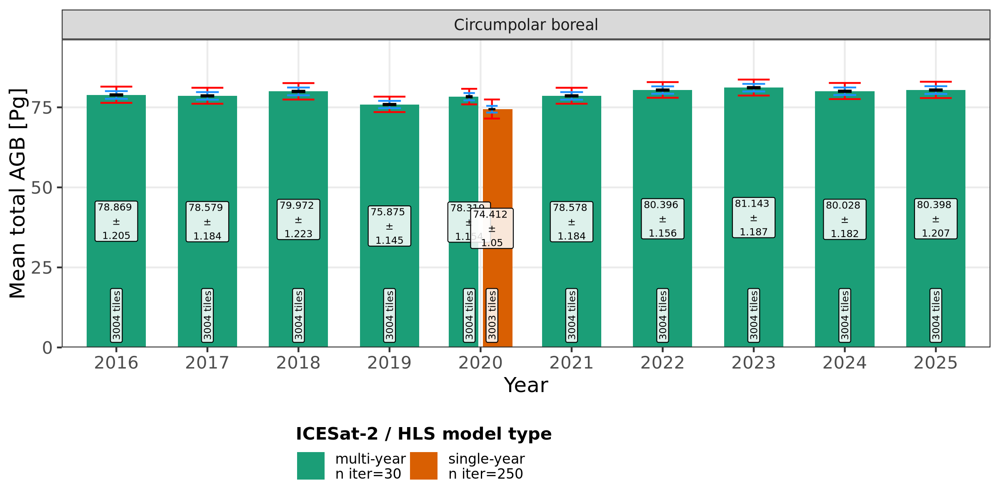

In [36]:
options(repr.plot.width = 8, repr.plot.height = 4, repr.plot.res = 300)

do_time_series_AGB(boreal_summary)  + 
   
   facet_wrap(~factor(domain), ncol=1, scales='free')

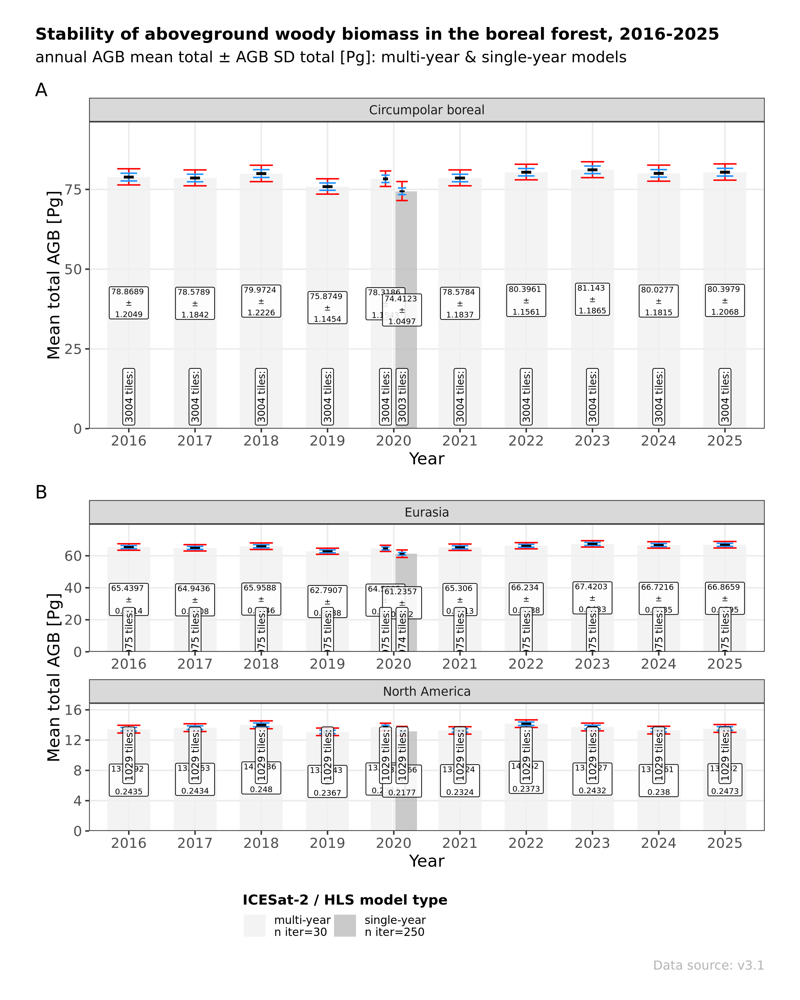

In [392]:
options(repr.plot.width = 8, repr.plot.height = 10, repr.plot.res = 300)

( (do_time_series_AGB(boreal_summary)  + 
   facet_wrap(~factor(domain), ncol=1, scales='free')) / (do_time_series_AGB(boreal_summary_realm) + facet_wrap(~factor(realm), ncol=1, scales='free')) ) +
plot_layout(guides = "collect") +
  plot_annotation(
    title = "Stability of aboveground woody biomass in the boreal forest, 2016-2025",
        subtitle = paste("annual AGB mean total ± AGB SD total [Pg]: multi-year & single-year models"),
    caption = 'Data source: v3.1',
    tag_levels = 'A',
    theme = theme(
      plot.title = element_text(size = 12, face = "bold", color = "black", hjust = 0),
      #plot.subtitle = element_text(size = 12, italic = TRUE, color = "darkblue", hjust = 0.5),
      plot.caption = element_text(size = 9, color = "gray70"),
      #plot.background = element_rect(fill = "aliceblue"),
      plot.margin = margin(20, 20, 20, 20),
        legend.position = 'bottom'
    )
  )

## Stability of AGB By Ecoregion
+ examine ecoregion AGB time-series
+ compute linear trend by ecoregion
+ examine apparent anomalous 2019 year

In [18]:
library(ggrepel)
library(RColorBrewer)

In [19]:
# Set threshold for significant change assocaited with apparent 2019 anomaly year
SIG_CHANGE_THRESH_SD <- 2

In [20]:
# ==============================================================================
# CONFIGURATION: Define plot specifications
# ==============================================================================

plot_specs <- list(
  ecoregions = list(
    data = boreal_summary_ecoregion,
    group_vars = c("eco_name", "realm", "biome_name"),
    order_var = "eco_name",
    facet_var = "realm + eco_name",
    facet_type = "wrap",
    facet_scales = "free_y",
    group_aes = "eco_name",
    color_var = "biome_name",
    trend_group_vars = c("realm", "biome_name", "eco_name"),
    title = "Decadal trends in total AGB for boreal and transitional ecoregions",
    ncol = 7
  ),
  biomes = list(
    data = boreal_summary_biome,
    group_vars = c("realm", "biome_name"),
    order_var = "biome_name",
    facet_var = "realm ~ biome_name",
    facet_type = "grid",
    facet_scales = "free_y",
    group_aes = "biome_name",
    color_var = "biome_name",
    trend_group_vars = c("realm", "biome_name"),
    title = "Decadal trends in total AGB by biome",
    ncol = NULL
  ),
  biomes_by_realm = list(
    data = boreal_summary_biome,
    group_vars = c("realm", "biome_name"),
    order_var = "biome_name",
    facet_var = "realm",
    facet_type = "wrap",
    facet_scales = "free_y",
    group_aes = "biome_name",
    color_var = "biome_name",
    trend_group_vars = c("realm", "biome_name"),
    title = "Decadal trends in total AGB by biome (faceted by realm)",
    ncol = 7
  ),
  biomes_by_biome = list(
    data = boreal_summary_biome,
    group_vars = c("realm", "biome_name"),
    order_var = "biome_name",
    facet_var = "biome_name",
    facet_type = "wrap",
    facet_scales = "free_y",
    group_aes = "realm",
    color_var = "realm",
    trend_group_vars = c("realm", "biome_name"),
    title = "Decadal trends in total AGB by biome (faceted by biome)",
    ncol = 3
  ),
  realm = list(
    data = boreal_summary_realm,
    group_vars = c("realm"),
    order_var = "realm",
    facet_var = "realm",
    facet_type = "wrap",
    facet_scales = "free_y",
    group_aes = "realm",
    color_var = "realm",
    trend_group_vars = c("realm"),
    title = "Decadal trends in total AGB by realm",
    ncol = 7
  ),
  circumpolar = list(
    data = boreal_summary,
    group_vars = c("n_tiles"),
    order_var = "n_tiles",
    facet_var = NULL,
    facet_type = NULL,
    facet_scales = NULL,
    group_aes = "n_tiles",
    color_var = NULL,
    trend_group_vars = c("n_tiles"),
    title = "Decadal trends in total AGB - Circumpolar domain",
    ncol = 1
  )
)

In [21]:
summarise_for_plot <- function(df, group_by_vars = c("eco_name", "realm", "biome_name", SIG_CHANGE_THRESH_SD=2)) {
    df_smry <- df %>%
        # Summarize across iter to get one value per group WITH PROPER UNCERTAINTY
        group_by(across(all_of(c(group_by_vars, "year")))) %>%
        summarise(
            mean_total_AGB_Pg = mean(mean_total_AGB_Pg, na.rm = TRUE),
            # Calculate SD across iterations (if iter column exists) or use existing SD
            sd_across_iter = sd(mean_total_AGB_Pg, na.rm = TRUE),
            # Keep the original spatial SD for reference
            spatial_sd = mean(sd_total_AGB_Pg, na.rm = TRUE),
            n_obs = n(),
            .groups = 'drop'
        ) %>%
        # Calculate 2019 anomaly using the threshold
        group_by(across(all_of(group_by_vars))) %>%
        mutate(
            # Calculate expected 2019 value from surrounding years
            expected_2019 = ifelse(year == 2019,
                                  mean(mean_total_AGB_Pg[year %in% c(2017, 2018, 2020, 2021)], na.rm = TRUE),
                                  NA),
            sd_surrounding = ifelse(year == 2019,
                                   sd(mean_total_AGB_Pg[year %in% c(2017, 2018, 2020, 2021)], na.rm = TRUE),
                                   NA),
            # Calculate if 2019 is anomalously low using the threshold
            is_2019_low = ifelse(year == 2019 & !is.na(expected_2019) & !is.na(sd_surrounding),
                                mean_total_AGB_Pg < (expected_2019 - (SIG_CHANGE_THRESH_SD * sd_surrounding)),
                                FALSE),
            # Propagate the anomaly flag to all years for this ecoregion
            has_2019_anomaly = any(is_2019_low, na.rm = TRUE)
        ) %>%
        ungroup() %>%
        # Convert to Tg and decide which SD to use for ribbons
        mutate(
            mean_total_AGB_Tg = mean_total_AGB_Pg * 1000,
            # Use SD across iterations if available and meaningful, otherwise use spatial SD
            sd_total_AGB_Tg = ifelse(!is.na(sd_across_iter) & sd_across_iter > 0, 
                                     sd_across_iter * 1000, 
                                     spatial_sd * 1000)
        ) 

    return(df_smry)
}

In [22]:
library(RColorBrewer)

In [23]:
# Get all unique biomes from your data
unique_biomes <- boreal_summary_biome %>% 
  pull(biome_name) %>% 
  unique() %>% #droplevels() %>%
  sort()

# Number of biomes
n_biomes <- length(unique_biomes)

# Get the palette with enough colors, reversed to start with darker
greens_colors <- rev(brewer.pal(n = max(1, min(n_biomes, 9)), name = "YlGn"))

# If you have more than 9 biomes, interpolate additional colors
if(n_biomes > 9) {
  greens_colors <- colorRampPalette(rev(brewer.pal(9, "YlGn")))(n_biomes)
}

# Create the named vector (color dictionary)
biome_colors <- setNames(greens_colors, unique_biomes)

# Create named vector (dictionary)
biome_color_dict <- setNames(biome_colors, unique_biomes)

# Print the dictionary
print(biome_color_dict)

                                   Biome 98 
                                  "#005A32" 
                       Boreal Forests/Taiga 
                                  "#238443" 
                 Deserts & Xeric Shrublands 
                                  "#41AB5D" 
            Montane Grasslands & Shrublands 
                                  "#78C679" 
        Temperate Broadleaf & Mixed Forests 
                                  "#ADDD8E" 
                  Temperate Conifer Forests 
                                  "#D9F0A3" 
Temperate Grasslands, Savannas & Shrublands 
                                  "#F7FCB9" 
                                     Tundra 
                                  "#FFFFE5" 


In [24]:
geom_legend_ecoregion_timeseries = list(
         # Specify legend layout here
            guides(
              color = guide_legend(
                nrow = 1, 
                byrow = TRUE,
                title.position = "top",
                label.position = "right",
                keywidth = unit(1, "lines"),      # Width of the color box
                keyheight = unit(1, "lines"),       # Height of the color box
                override.aes = list(size = 3)       # Size of legend points/keys
              ),
              fill = guide_legend(
                nrow = 1, 
                byrow = TRUE,
                title.position = "top",
                label.position = "right",
                keywidth = unit(1, "lines"),
                keyheight = unit(1, "lines")
              )
            ) 
    )
geom_theme_ecoregion_timeseries = list(
    theme_bw(base_size = 9),
    theme(
      # Move strips to left side with vertical text
      strip.background = element_rect(fill = "gray90", color = "gray50"),
      strip.text.y.right = element_text(
        face = "bold", 
        size = 7, 
        angle = 90,  # Horizontal text reading left to right
        hjust = 0,  # Left-aligned
        lineheight = 0.9,
        margin = margin(l = 2, r = 2)
      ),
      strip.placement = "inside",
      legend.position = "top",
        legend.text = element_text(size = 7, margin = margin(l = 3, r = 12)),  # Left margin from key ...handles text overlap?
      legend.title = element_text(size = 9, face = "bold"),
      axis.text.x = element_text(angle = 90, hjust = 1, vjust = 0.5, size = 8),
      axis.text.y = element_text(size = 8),
      axis.title = element_text(size = 10),
      plot.title = element_text(size = 12, face = "bold"),
      plot.subtitle = element_text(size = 9),
      panel.spacing.y = unit(0.5, "lines"),  # Vertical spacing between facets
      panel.spacing.x = unit(0.3, "lines")
    )
    )



# # View the colors
# scales::show_col(biome_color_dict)

In [58]:
# ==============================================================================
# FUNCTION: Calculate trend statistics
# ==============================================================================

calculate_trend_stats <- function(plot_data, group_vars) {
  trend_stats <- plot_data %>%
    group_by(across(all_of(group_vars))) %>%
    summarise(
      # Linear model statistics
      slope = coef(lm(mean_total_AGB_Tg ~ year))[2],
      intercept = coef(lm(mean_total_AGB_Tg ~ year))[1],
      r_squared = summary(lm(mean_total_AGB_Tg ~ year))$r.squared,
      p_value = summary(lm(mean_total_AGB_Tg ~ year))$coefficients[2, 4],
      # Additional statistics
      n_years = n(),
      mean_AGB = mean(mean_total_AGB_Tg, na.rm = TRUE),
      sd_AGB = sd(mean_total_AGB_Tg, na.rm = TRUE),
      # Trend direction and significance
      trend_direction = case_when(
        slope > 0 & p_value < 0.05 ~ "Increasing*",
        slope < 0 & p_value < 0.05 ~ "Decreasing*",
        slope > 0 ~ "Increasing",
        slope < 0 ~ "Decreasing",
        TRUE ~ "Stable"
      ),
      # Format for display
      slope_label = sprintf("%.4f Tg/yr", slope),
      r2_label = sprintf("R² = %.3f", r_squared),
      p_label = sprintf("p = %.3f", p_value),
      .groups = 'drop'
    )
  
  # Add has_2019_anomaly flag if eco_name exists
  if ("eco_name" %in% names(plot_data)) {
    trend_stats <- trend_stats %>%
      left_join(
        plot_data %>% 
          filter(has_2019_anomaly) %>% 
          distinct(eco_name, has_2019_anomaly),
        by = "eco_name"
      ) %>%
      mutate(has_2019_anomaly = replace_na(has_2019_anomaly, FALSE))
  } else if ("realm" %in% names(plot_data)) {
    trend_stats <- trend_stats %>%
      left_join(
        plot_data %>% 
          filter(has_2019_anomaly) %>% 
          distinct(realm, has_2019_anomaly),
        by = "realm"
      ) %>%
      mutate(has_2019_anomaly = replace_na(has_2019_anomaly, FALSE))
  }
  
  return(trend_stats)
}



# ==============================================================================
# PLOTTING FUNCTION: Create standardized plots
# ==============================================================================

create_timeseries_plot <- function(plot_data, trend_stats, spec, 
                                   show_trend = FALSE,
                                   highlight_2019 = FALSE,
                                   do_bars = FALSE,
                                   bar_data = NULL) {
  
  # Determine grouping variable for aesthetics
  group_var <- spec$group_aes
  color_var <- spec$color_var
  has_color <- !is.null(color_var) && color_var %in% names(plot_data)
  
  # Convert Pg columns to Tg if bar_data provided
  if (!is.null(bar_data)) {
    pg_cols <- grep("_Pg$", names(bar_data), value = TRUE)
    for (col in pg_cols) {
      new_col <- sub("_Pg$", "_Tg", col)
      bar_data[[new_col]] <- bar_data[[col]] * 1000
    }
  }

  # Calculate y-axis limits from plot_data (not bar_data)
  y_max <- max(plot_data$mean_total_AGB_Tg + plot_data$sd_total_AGB_Tg, na.rm = TRUE)
  y_min <- min(plot_data$mean_total_AGB_Tg - plot_data$sd_total_AGB_Tg, na.rm = TRUE)
  y_range <- y_max - y_min
  y_limits <- c(max(0, y_min - 0.05 * y_range), y_max + 0.05 * y_range)
  
  # Base plot
  p <- ggplot(plot_data, 
              aes(x = year, y = mean_total_AGB_Tg)) +
    geom_vline(xintercept = 2019, linetype = "dashed", alpha = 0.5)
  
  # Add bars behind if requested
  if (do_bars && !is.null(bar_data)) {
    p <- p + geom_col(data = bar_data,
                      aes(x = year, y = mean_total_AGB_Tg),
                      alpha = 1, 
                      width = 0.65,
                      fill = "gray70",
                      inherit.aes = FALSE)
  }
  
  # Add ribbon - check both biome_name and color_var
  if (has_color && "biome_name" %in% names(plot_data) && color_var == "biome_name") {
    p <- p + geom_ribbon(aes(ymin = mean_total_AGB_Tg - sd_total_AGB_Tg,
                             ymax = mean_total_AGB_Tg + sd_total_AGB_Tg,
                             fill = biome_name),
                         alpha = 0.5)
  } else if (has_color && "realm" %in% names(plot_data) && color_var == "realm") {
    p <- p + geom_ribbon(aes(ymin = mean_total_AGB_Tg - sd_total_AGB_Tg,
                             ymax = mean_total_AGB_Tg + sd_total_AGB_Tg,
                             fill = realm),
                         alpha = 0.5)
  } else {
    p <- p + geom_ribbon(aes_string(ymin = "mean_total_AGB_Tg - sd_total_AGB_Tg",
                                    ymax = "mean_total_AGB_Tg + sd_total_AGB_Tg",
                                    group = group_var),
                         alpha = 0.5, fill = "grey70")
  }
  
  # Add trend line if requested - MUST match the grouping structure
  if (show_trend) {
    # For single series per facet (ecoregions, realm, circumpolar)
    if (group_var %in% c("eco_name", "realm", "n_tiles")) {
      p <- p + geom_smooth(aes_string(group = group_var),
                           method = "lm",
                           se = TRUE,
                           alpha = 0.5,
                           color = 'black',
                           fill = 'gray',
                           linetype = "dashed",
                           size = 0.8)
    } else {
      # For multiple series per facet (biomes) - match to color variable
      if (has_color && color_var == "biome_name") {
        p <- p + geom_smooth(aes(group = biome_name),
                             method = "lm",
                             se = TRUE,
                             alpha = 0.5,
                             color = 'black',
                             fill = 'gray',
                             linetype = "dashed",
                             size = 0.8)
      } else if (has_color && color_var == "realm") {
        p <- p + geom_smooth(aes(group = realm),
                             method = "lm",
                             se = TRUE,
                             alpha = 0.5,
                             color = 'black',
                             fill = 'gray',
                             linetype = "dashed",
                             size = 0.8)
      }
    }
  }
  
  # Add lines
  if (has_color) {
    p <- p +
      geom_line(aes_string(color = color_var, group = group_var), size = 1) +
      geom_line(aes_string(group = group_var), color = 'black', size = 0.25)
  } else {
    p <- p + geom_line(aes_string(group = group_var), color = 'black', size = 1)
  }
  
  # Conditional point highlighting for 2019
  if (highlight_2019) {
    p <- p +
      geom_point(aes(size = year == 2019, alpha = year == 2019), color = 'black')
    
    if (has_color && color_var == "biome_name") {
      p <- p + geom_point(aes(fill = biome_name), shape = 21, color = 'black')
    } else if (has_color && color_var == "realm") {
      p <- p + geom_point(aes(fill = realm), shape = 21, color = 'black')
    } else {
      p <- p + geom_point(color = 'black', size = 2)
    }
    
    p <- p +
      scale_size_manual(values = c("FALSE" = 2, "TRUE" = 3), guide = "none") +
      scale_alpha_manual(values = c("FALSE" = 0.6, "TRUE" = 1), guide = "none")
  } else {
    if (has_color && color_var == "biome_name") {
      p <- p + geom_point(aes(fill = biome_name), shape = 21, color = 'black')
    } else if (has_color && color_var == "realm") {
      p <- p + geom_point(aes(fill = realm), shape = 21, color = 'black')
    } else {
      p <- p + geom_point(color = 'black', size = 2)
    }
  }
  
# Add trend labels if trend stats provided and show_trend is TRUE
  if (show_trend && !is.null(trend_stats)) {
    # Prepare trend label data based on aggregation level
    if ("eco_name" %in% names(trend_stats)) {
      # Ecoregions - one label per facet
      trend_label_data <- trend_stats %>%
        mutate(
          eco_name_abbrev = eco_name %>%
            str_replace_all("Mountains", "Mtns") %>%
            str_replace_all(" and ", " & "),
          combined_label = paste0(trend_direction, "\n", slope_label, "\n", r2_label)
        )
      
      # Add label at top of each facet
      p <- p + geom_label(data = trend_label_data,
                         aes(x = 2021, y = Inf, label = combined_label),
                         vjust = 1.2, hjust = 0.5,
                         size = 2.5,
                         fill = "white",
                         alpha = 1,
                         label.padding = unit(0.15, "lines"),
                         lineheight = 0.8,
                         show.legend = FALSE,
                         inherit.aes = FALSE)
      
    } else if ("biome_name" %in% names(trend_stats) && "realm" %in% names(trend_stats)) {
      # Biomes - multiple labels per facet, need to position to avoid overlap
      
      # Position labels based on which variable we're faceting by
      if (spec$facet_var == "realm ~ biome_name") {
        # Grid layout - one label per cell
        trend_label_data <- trend_stats %>%
          mutate(
            combined_label = paste0(trend_direction, "\n", slope_label, "\n", r2_label)
          )
        
        p <- p + geom_label(data = trend_label_data,
                           aes(x = 2021, y = Inf, label = combined_label),
                           vjust = 1.2, hjust = 0.5,
                           size = 2.5,
                           fill = "white",
                           alpha = 1,
                           label.padding = unit(0.15, "lines"),
                           lineheight = 0.8,
                           show.legend = FALSE,
                           inherit.aes = FALSE)
                           
      } else if (spec$facet_var == "realm") {
        # Faceted by realm - multiple biomes per facet
        # Get max values per facet to position labels relative to data
        max_values <- plot_data %>%
          group_by(realm) %>%
          summarise(max_y = max(mean_total_AGB_Tg + sd_total_AGB_Tg, na.rm = TRUE),
                   .groups = 'drop')
        
        trend_label_data <- trend_stats %>%
          left_join(max_values, by = "realm") %>%
          group_by(realm) %>%
          arrange(biome_name) %>%
          mutate(
            label_rank = row_number() - 1,
            combined_label = paste0(trend_direction, "\n", slope_label, "\n", r2_label),
            # Calculate y position as percentage below max
            label_y = max_y * (1 - 0.02 - label_rank * 0.12)
          ) %>%
          ungroup()
        
        p <- p + geom_label(data = trend_label_data,
                           aes(x = 2020, y = label_y, label = combined_label),
                           vjust = 1, hjust = 0.5,
                           size = 2.3,
                           fill = "white",
                           alpha = 0.9,
                           label.padding = unit(0.15, "lines"),
                           lineheight = 0.8,
                           show.legend = FALSE,
                           inherit.aes = FALSE)
                           
      } else if (spec$facet_var == "biome_name") {
        # Faceted by biome - multiple realms per facet
        # Get max values per facet to position labels relative to data
        max_values <- plot_data %>%
          group_by(biome_name) %>%
          summarise(max_y = max(mean_total_AGB_Tg + sd_total_AGB_Tg, na.rm = TRUE),
                   .groups = 'drop')
        
        trend_label_data <- trend_stats %>%
          left_join(max_values, by = "biome_name") %>%
          group_by(biome_name) %>%
          arrange(realm) %>%
          mutate(
            label_rank = row_number() - 1,
            combined_label = paste0(trend_direction, "\n", slope_label, "\n", r2_label),
            # Calculate y position as percentage below max
            label_y = max_y * (1 - 0.02 - label_rank * 0.12)
          ) %>%
          ungroup()
        
        p <- p + geom_label(data = trend_label_data,
                           aes(x = 2020, y = label_y, label = combined_label),
                           vjust = 1, hjust = 0.5,
                           size = 2.3,
                           fill = "white",
                           alpha = 0.9,
                           label.padding = unit(0.15, "lines"),
                           lineheight = 0.8,
                           show.legend = FALSE,
                           inherit.aes = FALSE)
      }
      
    } else if ("realm" %in% names(trend_stats)) {
      # Realm - one label per facet
      trend_label_data <- trend_stats %>%
        mutate(
          combined_label = paste0(trend_direction, "\n", slope_label, "\n", r2_label)
        )
      
      p <- p + geom_label(data = trend_label_data,
                         aes(x = 2021, y = Inf, label = combined_label),
                         vjust = 1.2, hjust = 0.5,
                         size = 2.5,
                         fill = "white",
                         alpha = 1,
                         label.padding = unit(0.15, "lines"),
                         lineheight = 0.8,
                         show.legend = FALSE,
                         inherit.aes = FALSE)
    } else {
      # Circumpolar - single label
      trend_label_data <- trend_stats %>%
        mutate(
          combined_label = paste0(trend_direction, "\n", slope_label, "\n", r2_label)
        )
      
      p <- p + geom_label(data = trend_label_data,
                         aes(x = 2021, y = Inf, label = combined_label),
                         vjust = 1.2, hjust = 0.5,
                         size = 2.5,
                         fill = "white",
                         alpha = 1,
                         label.padding = unit(0.15, "lines"),
                         lineheight = 0.8,
                         show.legend = FALSE,
                         inherit.aes = FALSE)
    }
  }
  
  # Add colors - handle both biome_name and realm coloring
  if (has_color && color_var == "biome_name") {
    p <- p +
      scale_color_manual(name = "Biome", values = biome_colors) +
      scale_fill_manual(name = "Biome", values = biome_colors)
  } else if (has_color && color_var == "realm") {
    # You may want to define realm_colors similar to biome_colors
    p <- p +
      scale_color_discrete(name = "Realm") +
      scale_fill_discrete(name = "Realm")
  }
  
  # Add labels and theme
  p <- p +
    labs(
      title = spec$title,
      subtitle = if(show_trend) "Linear trends (2016-2025)" else "",
      x = "Year",
      y = "Mean Total AGB (Tg)"
    ) +
    geom_legend_ecoregion_timeseries +
    geom_theme_ecoregion_timeseries +
    coord_cartesian(xlim = c(2016, 2025), clip = "off") +
    scale_x_continuous(breaks = seq(2016, 2025, by = 3),
                      labels = seq(2016, 2025, by = 3))
  
  # Add faceting if specified - support both wrap and grid
  if (!is.null(spec$facet_var)) {
    if (spec$facet_type == "grid") {
      p <- p + facet_grid(as.formula(spec$facet_var),
                         scales = spec$facet_scales,
                         switch = "y")
    } else {
      p <- p + facet_wrap(as.formula(paste("~", spec$facet_var)),
                         scales = spec$facet_scales,
                         switch = "y",
                         ncol = spec$ncol)
    }
  }
  
  return(p)
}

In [59]:
# ==============================================================================
# ANOMALY PLOT (for ecoregions only)
# ==============================================================================

create_anomaly_plot <- function(plot_data) {
  anomalous_ecoregions <- plot_data %>% 
    filter(has_2019_anomaly) %>% 
    pull(eco_name) %>% 
    unique()
  
  if(length(anomalous_ecoregions) == 0) {
    message("No anomalous ecoregions detected")
    return(NULL)
  }
  
  anomaly_plot_data <- plot_data %>% 
    filter(eco_name %in% anomalous_ecoregions) %>%
    mutate(
      eco_name_abbrev = str_replace_all(eco_name, "Mountains", "Mtns"),
      facet_label = paste0(eco_name_abbrev, " [", realm, "]"),
      facet_order = paste(realm, biome_name, eco_name, sep = "_")
    ) %>%
    arrange(realm, biome_name, eco_name) %>%
    mutate(facet_label = factor(facet_label, levels = unique(facet_label)))
  
  p <- ggplot(anomaly_plot_data,
              aes(x = year, y = mean_total_AGB_Tg, group = eco_name)) +
    geom_vline(xintercept = 2019, linetype = "dashed", alpha = 0.5) +
    geom_ribbon(aes(ymin = mean_total_AGB_Tg - sd_total_AGB_Tg,
                    ymax = mean_total_AGB_Tg + sd_total_AGB_Tg,
                    fill = biome_name),
                alpha = 0.5) +
    geom_line(aes(color = biome_name), size = 1) +
    geom_line(color = 'black', size = 0.25) +
    geom_point(aes(size = year == 2019, alpha = year == 2019), color = 'red') +
    geom_point(aes(fill = biome_name), shape = 21, color = 'black') +
    scale_color_manual(name = "Biome", values = biome_colors) +
    scale_fill_manual(name = "Biome", values = biome_colors) +
    scale_size_manual(values = c("FALSE" = 2, "TRUE" = 3), guide = "none") +
    scale_alpha_manual(values = c("FALSE" = 0.6, "TRUE" = 1), guide = "none") +
    labs(
      title = "Decadal AGB time-series for ecoregions with prominent 2019 anomalies",
      subtitle = sprintf("Red circles mark the anomalously low 2019 values (>%d SD below mean)", 
                        SIG_CHANGE_THRESH_SD),
      x = "Year",
      y = "Mean Total AGB (Tg)"
    ) +
    geom_legend_ecoregion_timeseries +
    geom_theme_ecoregion_timeseries +
    coord_cartesian(xlim = c(2016, 2025), ylim = y_limits, clip = "off") +  # Added ylim here
    scale_x_continuous(breaks = seq(2016, 2025, by = 1),
                      labels = seq(2016, 2025, by = 1)) +
    facet_wrap(~ facet_label, scales = "free_y", 
               #switch = "x", 
               ncol = 4)
  
  return(p)
}

In [60]:
# ==============================================================================
# DATA PREPARATION: Process all datasets at once
# ==============================================================================

plot_data_list <- lapply(names(plot_specs), function(name) {
  spec <- plot_specs[[name]]
  
  summarise_for_plot(spec$data, group_by_vars = spec$group_vars) %>%
    reorder_facets_by_column(spec$order_var, 'mean_total_AGB_Pg')
})
names(plot_data_list) <- names(plot_specs)


In [61]:
# Calculate trend stats for all datasets
trend_stats_list <- lapply(names(plot_specs), function(name) {
  calculate_trend_stats(plot_data_list[[name]], 
                       plot_specs[[name]]$trend_group_vars)
})
names(trend_stats_list) <- names(plot_specs)

In [62]:
# ==============================================================================
# GENERATE PLOTS
# ==============================================================================

# Generate all main plots
plots <- lapply(names(plot_specs), function(name) {
  list(
    basic = create_timeseries_plot(plot_data_list[[name]], 
                                   NULL,
                                   plot_specs[[name]], 
                                   show_trend = FALSE,
                                   highlight_2019 = FALSE),
    trend = create_timeseries_plot(plot_data_list[[name]], 
                                   trend_stats_list[[name]],
                                   plot_specs[[name]], 
                                   show_trend = TRUE,
                                   highlight_2019 = FALSE),
    highlight = create_timeseries_plot(plot_data_list[[name]], 
                                       NULL,
                                       plot_specs[[name]], 
                                       show_trend = FALSE,
                                       highlight_2019 = TRUE)
  )
})

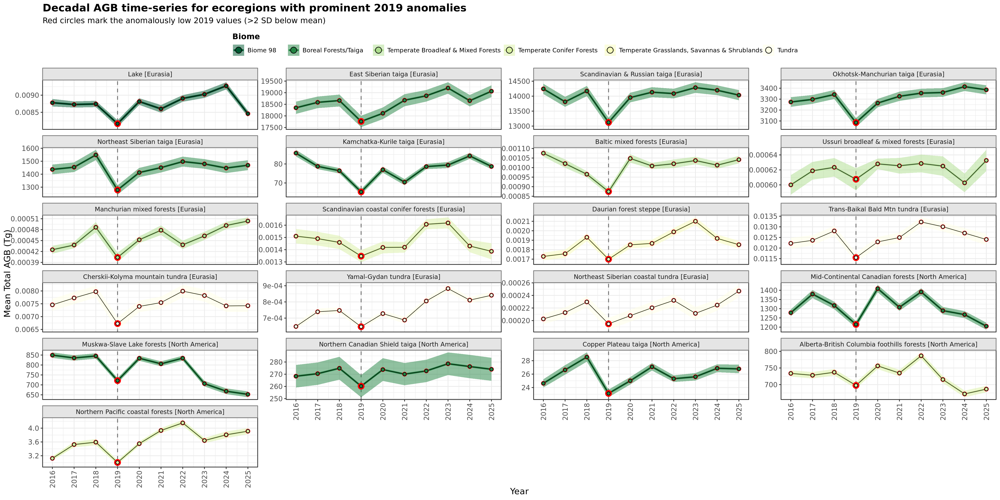

In [91]:
options(repr.plot.width = 16, repr.plot.height = 8, repr.plot.res = 300)

# Create anomaly plot
p_anomaly <- create_anomaly_plot(plot_data_list$ecoregions)
if(!is.null(p_anomaly)) print(p_anomaly)

In [30]:
names(plots) <- names(plot_specs)

In [31]:
names(plot_specs)

[1] "ecoregions"      "biomes"          "biomes_by_realm" "biomes_by_biome"
[5] "realm"           "circumpolar"

## Custom plots: ribbons are +/- 1 SD

In [50]:
head(boreal_summary_realm)

,year,RELEASE_VERSION,IDENTIFIER,realm,min_total_AGB_Pg,max_total_AGB_Pg,mean_total_AGB_Pg,median_total_AGB_Pg,sd_total_AGB_Pg,se_total_AGB_Pg,range_total_AGB_Pg,cv_total_AGB_Pg,q25_total_AGB_Pg,q75_total_AGB_Pg,min_rank,max_rank,n_ranks,n_tiles_avg,n_tiles
,<int>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<int>
1,2016,v3.1.0,multi-year n iter=30,Eurasia,63.46888,67.51377,65.43967,65.42698,0.9614049,0.17552772,4.044889,1.469147,64.79611,66.06136,1,30,30,1975,1975
2,2016,v3.1.0,multi-year n iter=30,North America,12.93640,13.95901,13.42923,13.42463,0.2434632,0.04445009,1.022609,1.812935,13.26607,13.58581,1,30,30,1029,1029
3,2017,v3.1.0,multi-year n iter=30,Eurasia,62.99768,66.95888,64.94359,64.93137,0.9408363,0.17177242,3.961194,1.448698,64.31282,65.55707,1,30,30,1975,1975
4,2017,v3.1.0,multi-year n iter=30,North America,13.13248,14.15689,13.63533,13.63059,0.2433763,0.04443424,1.024404,1.784896,13.47530,13.79453,1,30,30,1029,1029
5,2018,v3.1.0,multi-year n iter=30,Eurasia,63.93486,68.03621,65.95882,65.94887,0.9746340,0.17794301,4.101344,1.477640,65.30893,66.59560,1,30,30,1975,1975
6,2018,v3.1.0,multi-year n iter=30,North America,13.50482,14.54042,14.01362,14.00971,0.2479907,0.04527670,1.035596,1.769640,13.84856,14.17526,1,30,30,1029,1029


`geom_smooth()` using formula = 'y ~ x'


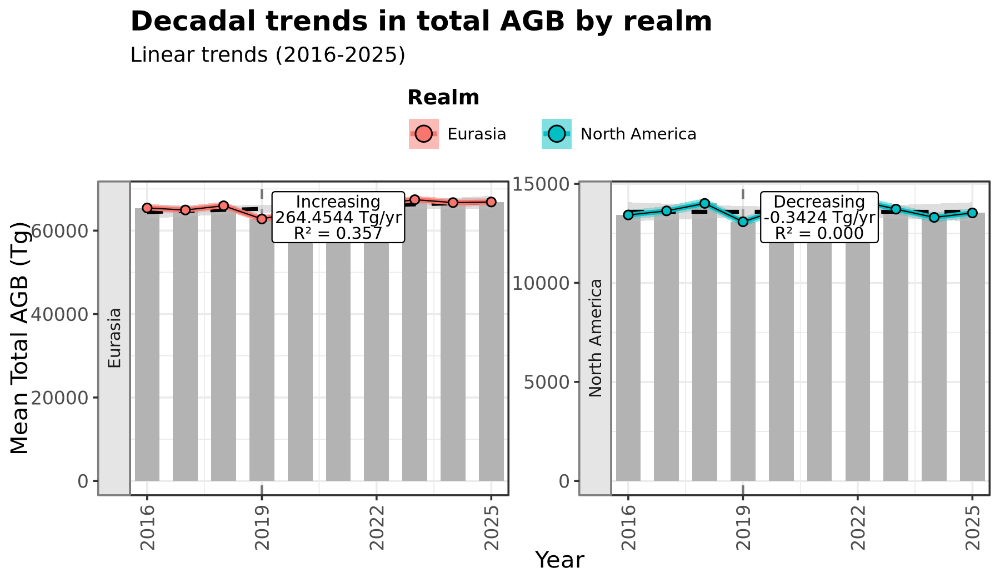

In [63]:
options(repr.plot.width = 6, repr.plot.height = 3.5, repr.plot.res = 300)

p_trend_realm = create_timeseries_plot(plot_data_list[['realm']], 
                                   trend_stats_list[['realm']],
                                   plot_specs[['realm']], 
                                   show_trend = TRUE, do_bars=TRUE, bar_data = boreal_summary_realm,
                                   highlight_2019 = FALSE)
p_trend_realm + lim

In [37]:
options(repr.plot.width = 6, repr.plot.height = 3, repr.plot.res = 300)

p_trend_circumpolar = create_timeseries_plot(plot_data_list[['circumpolar']] , 
                                   trend_stats_list[['circumpolar']] ,
                                   plot_specs[['circumpolar']], 
                                   show_trend = TRUE,
                                   highlight_2019 = FALSE)

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


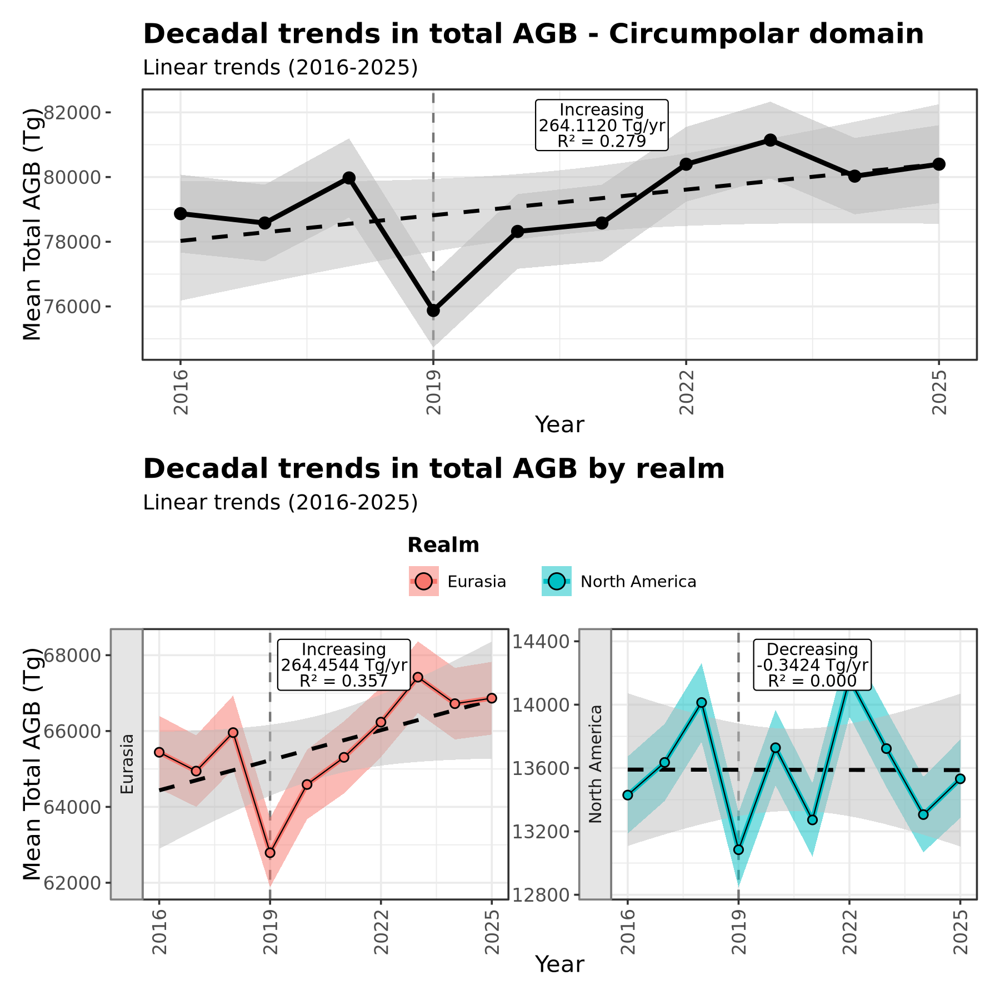

In [40]:
options(repr.plot.width = 6, repr.plot.height =6, repr.plot.res = 300)

p_trend_circumpolar / p_trend_realm

`geom_smooth()` using formula = 'y ~ x'


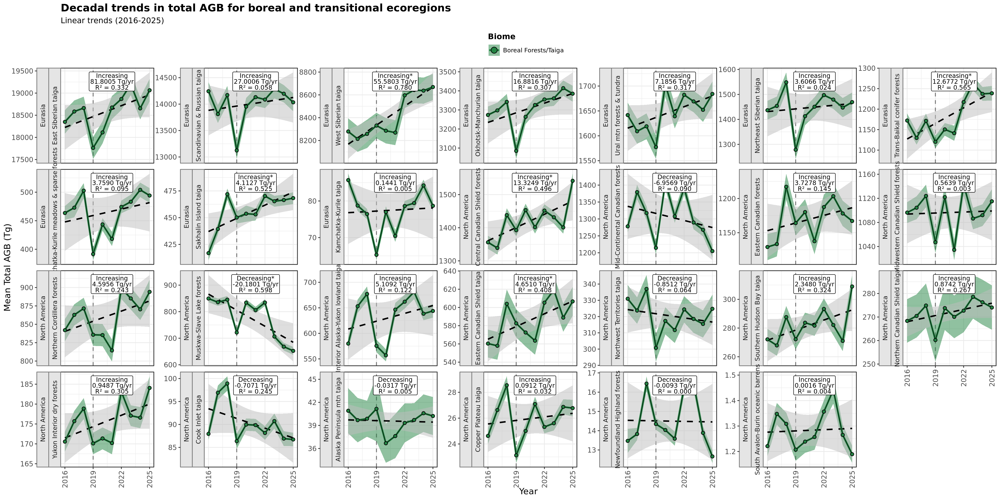

In [123]:
options(repr.plot.width = 16, repr.plot.height = 8, repr.plot.res = 300)

create_timeseries_plot(plot_data_list[['ecoregions']] %>% filter(biome_name == 'Boreal Forests/Taiga'), 
                                   trend_stats_list[['ecoregions']] %>% filter(biome_name == 'Boreal Forests/Taiga'),
                                   plot_specs[['ecoregions']], 
                                   show_trend = TRUE,
                                   highlight_2019 = FALSE)

In [147]:
tempcon_ecoregions_decreasing = (trend_stats_list[['ecoregions']] %>% filter(biome_name == 'Temperate Conifer Forests') %>% filter(trend_direction == 'Decreasing'))$eco_name
tempcon_ecoregions_increasing = (trend_stats_list[['ecoregions']] %>% filter(biome_name == 'Temperate Conifer Forests') %>% filter(trend_direction == 'Increasing'))$eco_name

`geom_smooth()` using formula = 'y ~ x'


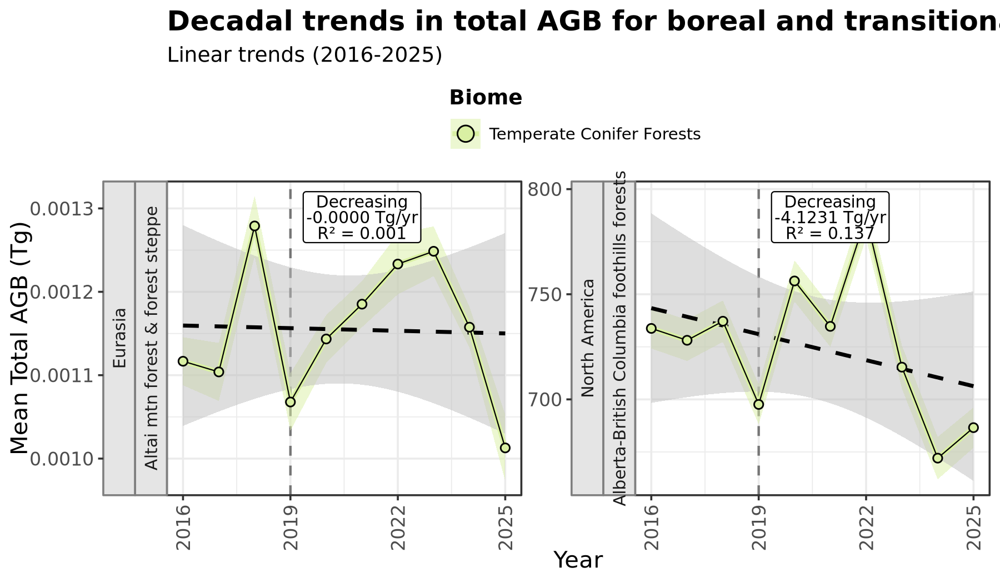

In [152]:
options(repr.plot.width = 6, repr.plot.height = 3.5, repr.plot.res = 300)

create_timeseries_plot(plot_data_list[['ecoregions']] %>% filter(eco_name %in% tempcon_ecoregions_decreasing), 
                                   trend_stats_list[['ecoregions']] %>% filter(eco_name %in% tempcon_ecoregions_decreasing),
                                   plot_specs[['ecoregions']], 
                                   show_trend = TRUE,
                                   highlight_2019 = FALSE)

`geom_smooth()` using formula = 'y ~ x'


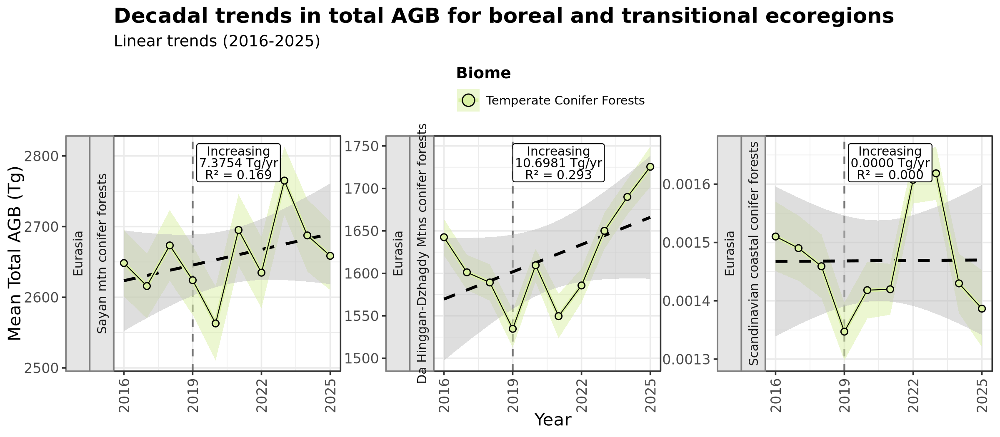

In [154]:
options(repr.plot.width = 8, repr.plot.height = 3.5, repr.plot.res = 300)

create_timeseries_plot(plot_data_list[['ecoregions']] %>% filter(eco_name %in% tempcon_ecoregions_increasing), 
                                   trend_stats_list[['ecoregions']] %>% filter(eco_name %in% tempcon_ecoregions_increasing),
                                   plot_specs[['ecoregions']], 
                                   show_trend = TRUE,
                                   highlight_2019 = FALSE)

In [140]:
boreal_ecoregions_decreasing = (trend_stats_list[['ecoregions']] %>% filter(biome_name == 'Boreal Forests/Taiga') %>% filter(trend_direction == 'Decreasing'))$eco_name
boreal_ecoregions_increasing = (trend_stats_list[['ecoregions']] %>% filter(biome_name == 'Boreal Forests/Taiga') %>% filter(trend_direction == 'Increasing'))$eco_name

`geom_smooth()` using formula = 'y ~ x'


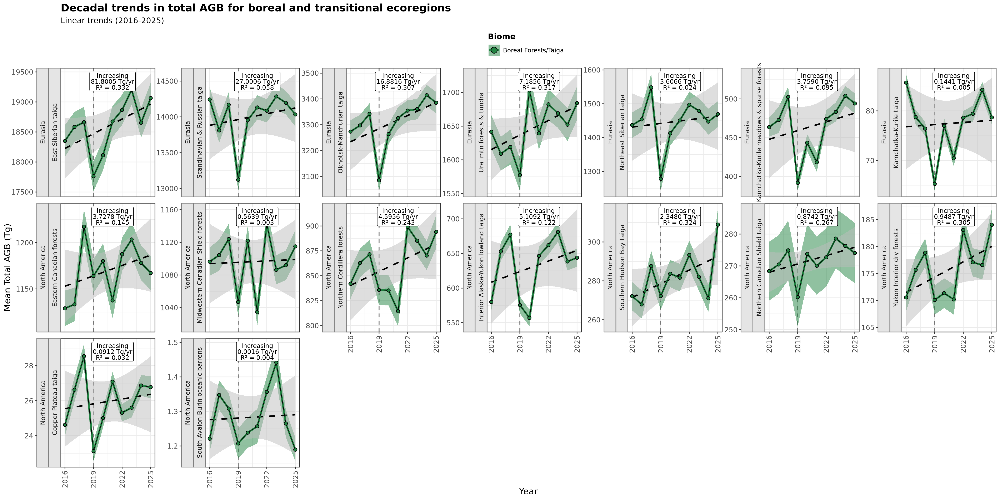

In [149]:
options(repr.plot.width = 16, repr.plot.height = 8, repr.plot.res = 300)

create_timeseries_plot(plot_data_list[['ecoregions']] %>% filter(eco_name %in% boreal_ecoregions_increasing), 
                                   trend_stats_list[['ecoregions']] %>% filter(eco_name %in% boreal_ecoregions_increasing),
                                   plot_specs[['ecoregions']], 
                                   show_trend = TRUE,
                                   highlight_2019 = FALSE)

`geom_smooth()` using formula = 'y ~ x'


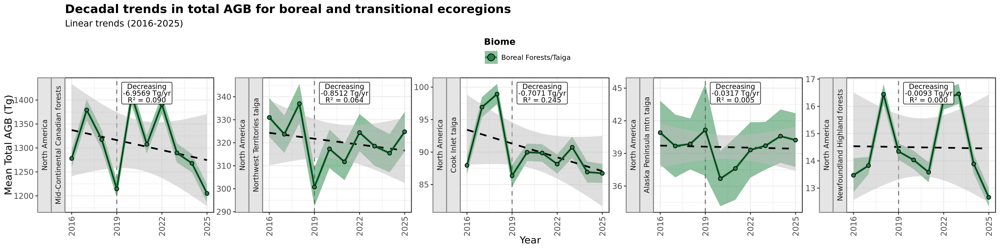

In [144]:
options(repr.plot.width = 14, repr.plot.height = 3.5, repr.plot.res = 300)

create_timeseries_plot(plot_data_list[['ecoregions']] %>% filter(biome_name == 'Boreal Forests/Taiga') %>% filter(eco_name %in% boreal_ecoregions_decreasing), 
                                   trend_stats_list[['ecoregions']] %>% filter(eco_name %in% boreal_ecoregions_decreasing),
                                   plot_specs[['ecoregions']], 
                                   show_trend = TRUE,
                                   highlight_2019 = FALSE)

`geom_smooth()` using formula = 'y ~ x'


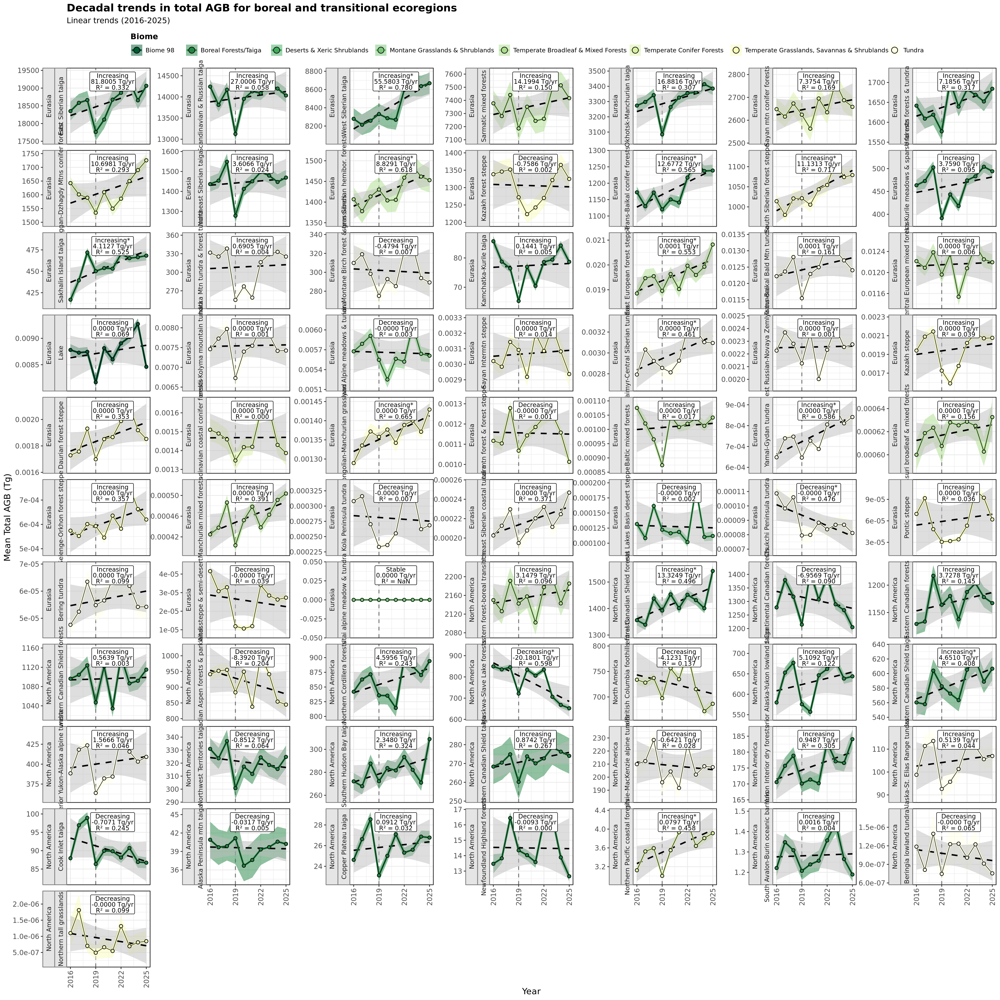

In [108]:
options(repr.plot.width = 16, repr.plot.height = 16, repr.plot.res = 300)

plots[[1]]$trend

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


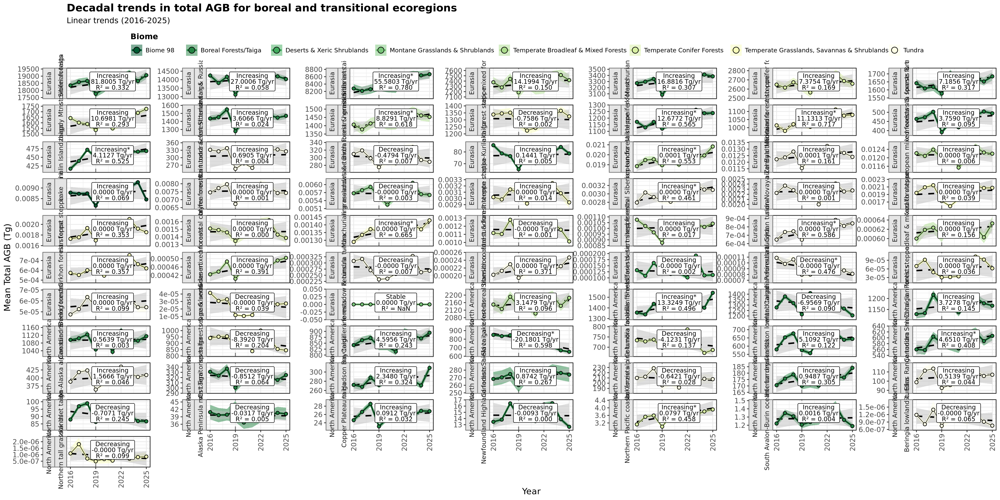

`geom_smooth()` using formula = 'y ~ x'


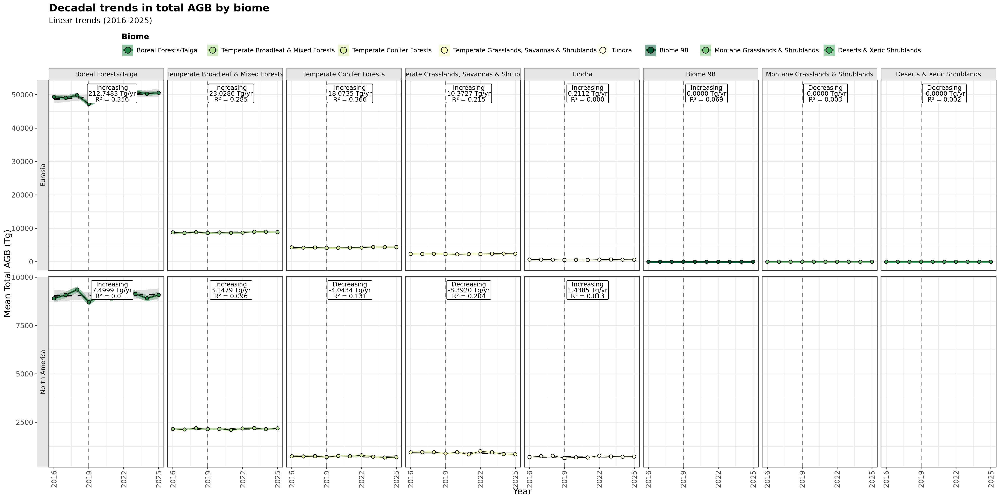

`geom_smooth()` using formula = 'y ~ x'


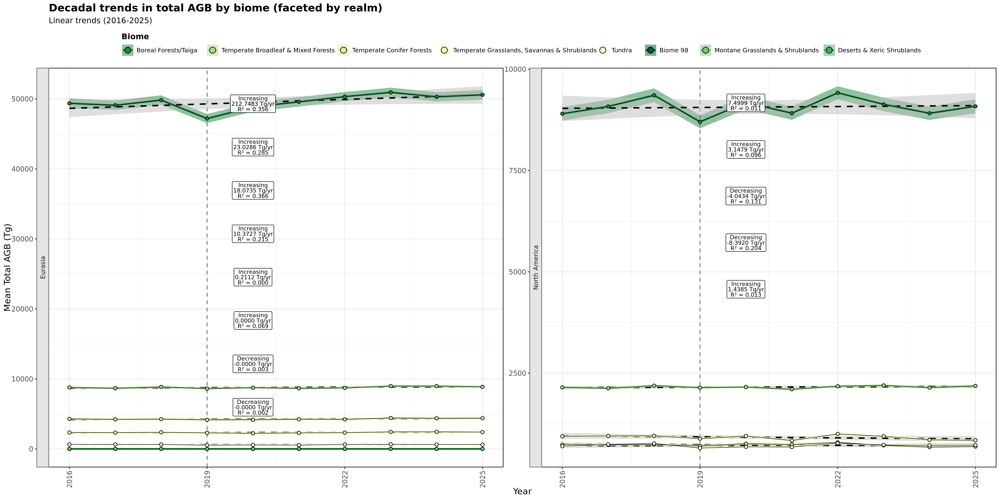

`geom_smooth()` using formula = 'y ~ x'


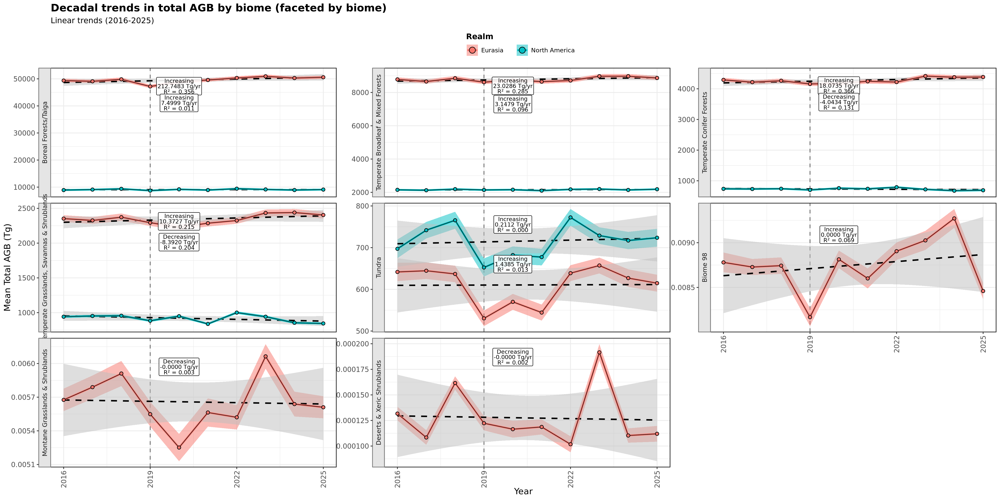

`geom_smooth()` using formula = 'y ~ x'


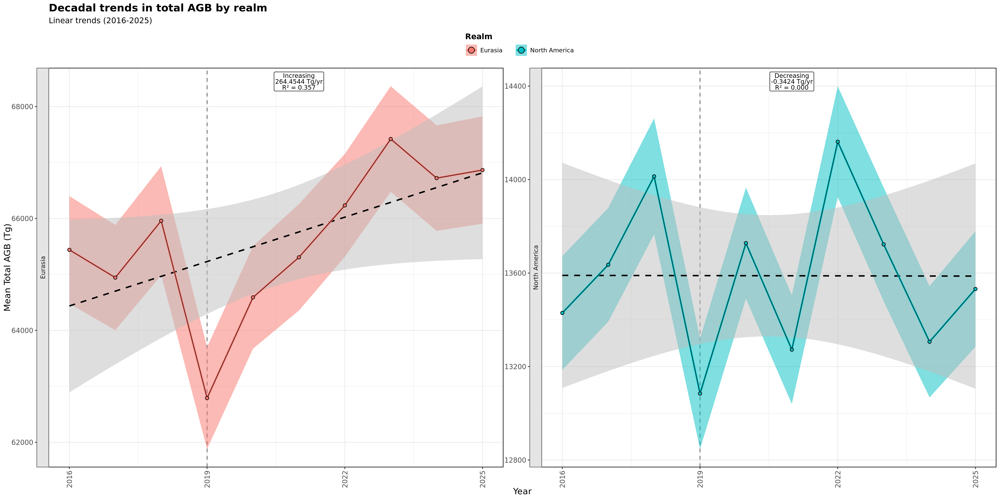

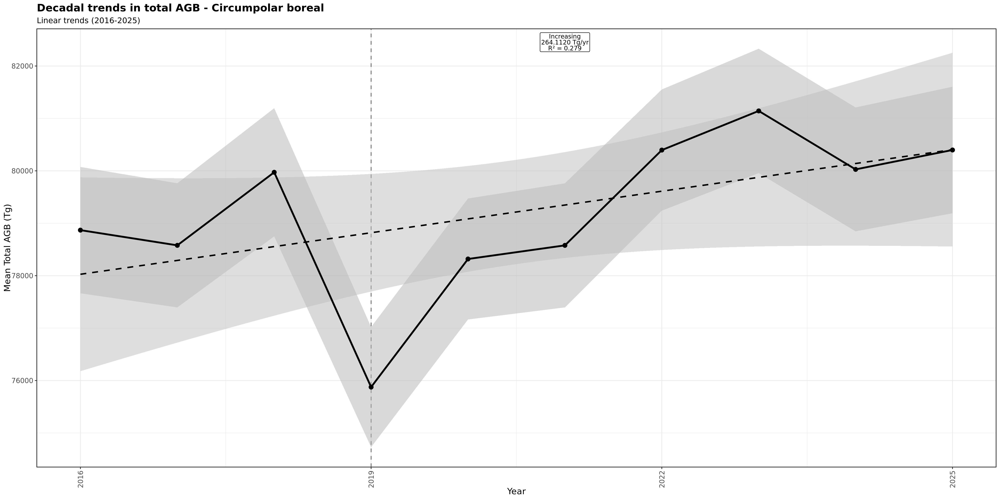

In [95]:
# Print plots (examples)
print(plots$ecoregions$trend)
print(plots$biomes$trend)
print(plots$biomes_by_realm$trend)
print(plots$biomes_by_biome$trend)
print(plots$realm$trend)
print(plots$circumpolar$trend)

In [787]:
library(patchwork)

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 3, repr.plot.res = 300)

print(plots$realm$trend)
print(plots$circumpolar$trend)



`geom_smooth()` using formula = 'y ~ x'


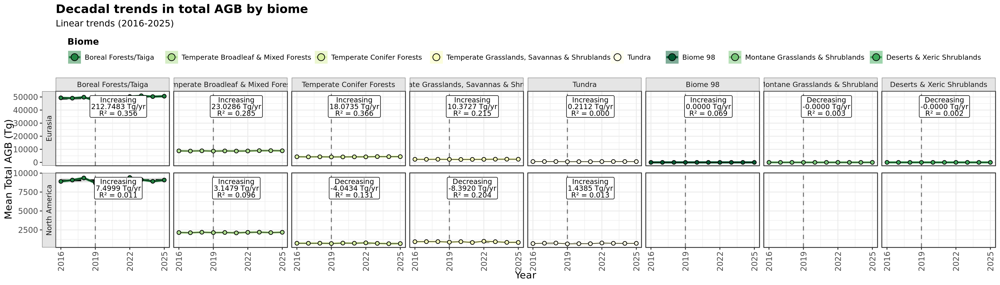

In [767]:
options(repr.plot.width = 14, repr.plot.height = 4, repr.plot.res = 300)

print(plots$biomes$trend)

`geom_smooth()` using formula = 'y ~ x'


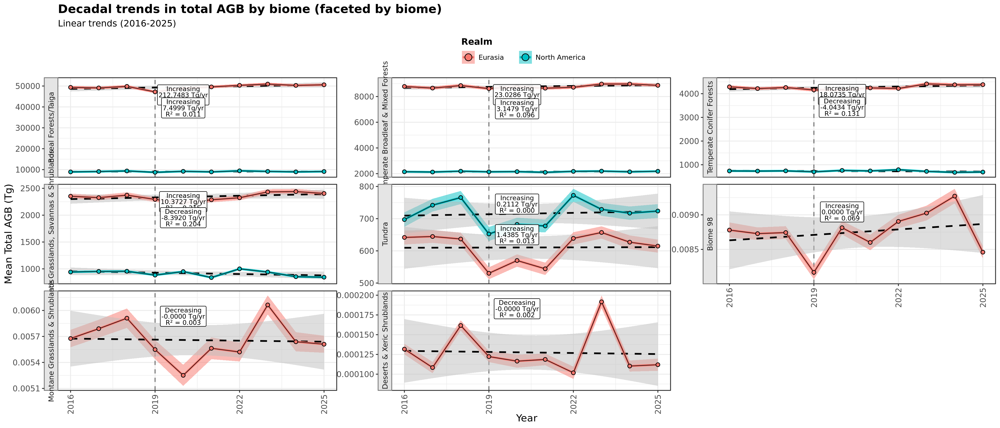

In [765]:
options(repr.plot.width = 14, repr.plot.height = 6, repr.plot.res = 300)

print(plots$biomes_by_biome$trend)       # Wrap by biome, color by realm

`geom_smooth()` using formula = 'y ~ x'


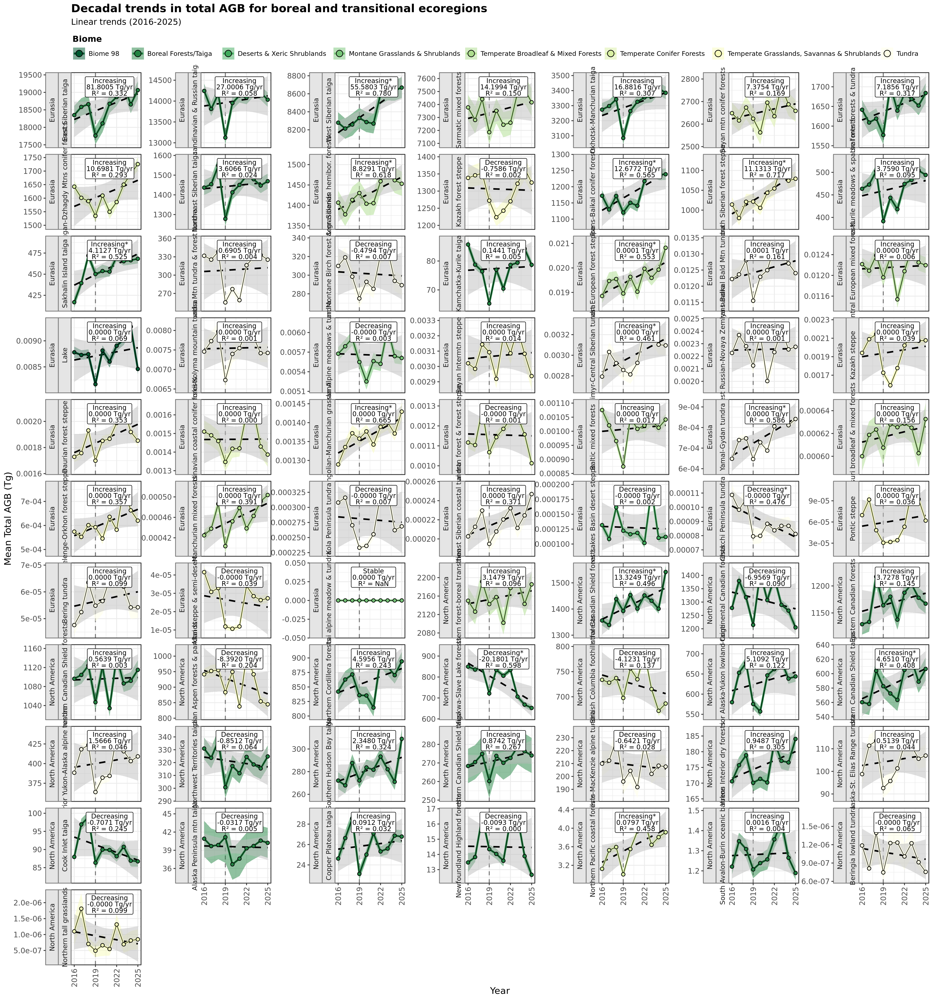

In [766]:
options(repr.plot.width = 14, repr.plot.height = 15, repr.plot.res = 300)

print(plots$ecoregions$trend)


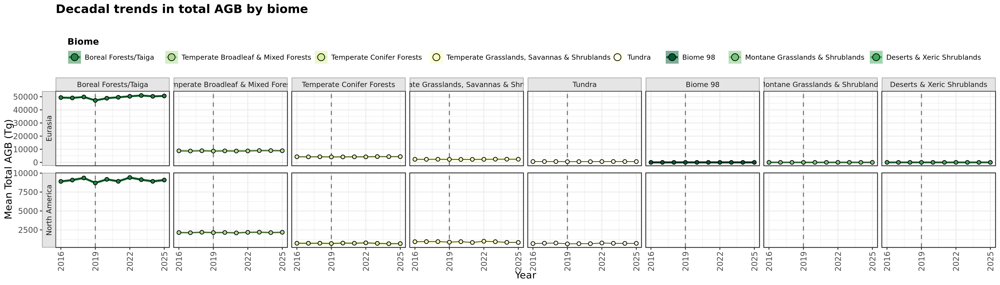

In [755]:
options(repr.plot.width = 14, repr.plot.height = 4, repr.plot.res = 300)

print(plots$biomes$basic)

# Old stuff
#### Ecoregion plot customizations

## Linear trend time-series

#### Prepare plot data

### Ecoregions, biomes, relmas, circumpolar

In [702]:
# First, prepare the data with 2019 anomaly detection
plot_data_ecoregions <- summarise_for_plot(boreal_summary_ecoregion, group_by_vars = c("eco_name", "realm", "biome_name")) %>%
        reorder_facets_by_column('eco_name','mean_total_AGB_Pg')
plot_data_biomes <- summarise_for_plot(boreal_summary_biome , group_by_vars = c('realm', 'biome_name' ))%>%
        reorder_facets_by_column('biome_name','mean_total_AGB_Pg')
plot_data_realm <- summarise_for_plot(boreal_summary_realm , group_by_vars = c('realm' ))%>%
        reorder_facets_by_column('realm','mean_total_AGB_Pg')  
plot_data_circumpolar <- summarise_for_plot(boreal_summary , group_by_vars = c('n_tiles' ))%>%
        reorder_facets_by_column('n_tiles','mean_total_AGB_Pg')  

In [722]:
head(plot_data_biomes)

realm,biome_name,year,mean_total_AGB_Pg,sd_across_iter,spatial_sd,n_obs,expected_2019,sd_surrounding,is_2019_low,has_2019_anomaly,mean_total_AGB_Tg,sd_total_AGB_Tg
<chr>,<fct>,<int>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>
Eurasia,Biome 98,2016,8.779872e-06,NA,1.105526e-07,1,NA,NA,FALSE,TRUE,0.008779872,1.105526e-04
Eurasia,Biome 98,2017,8.728004e-06,NA,9.034723e-08,1,NA,NA,FALSE,TRUE,0.008728004,9.034723e-05
Eurasia,Biome 98,2018,8.743600e-06,NA,9.233895e-08,1,NA,NA,FALSE,TRUE,0.008743600,9.233895e-05
Eurasia,Biome 98,2019,8.167630e-06,NA,1.002392e-07,1,8.721542e-06,8.889554e-08,TRUE,TRUE,0.008167630,1.002392e-04
Eurasia,Biome 98,2020,8.813988e-06,NA,9.775113e-08,1,NA,NA,FALSE,TRUE,0.008813988,9.775113e-05
Eurasia,Biome 98,2021,8.600576e-06,NA,1.116885e-07,1,NA,NA,FALSE,TRUE,0.008600576,1.116885e-04


#### Compute linear trend

In [723]:
# Calculate trend statistics for each ecoregion
trend_stats_ecoregions <- plot_data_ecoregions %>%
            group_by(realm, biome_name, eco_name) %>%
            # Fit linear model for each ecoregion
            summarise(
            # Linear model statistics
            slope = coef(lm(mean_total_AGB_Tg ~ year))[2],
            intercept = coef(lm(mean_total_AGB_Tg ~ year))[1],
            r_squared = summary(lm(mean_total_AGB_Tg ~ year))$r.squared,
            p_value = summary(lm(mean_total_AGB_Tg ~ year))$coefficients[2, 4],
            # Additional statistics
            n_years = n(),
            mean_AGB = mean(mean_total_AGB_Tg, na.rm = TRUE),
            sd_AGB = sd(mean_total_AGB_Tg, na.rm = TRUE),
            # Trend direction and significance
            trend_direction = case_when(
              slope > 0 & p_value < 0.05 ~ "Increasing*",
              slope < 0 & p_value < 0.05 ~ "Decreasing*",
              slope > 0 ~ "Increasing",
              slope < 0 ~ "Decreasing",
              TRUE ~ "Stable"
            ),
            # Format for display
            slope_label = sprintf("%.4f Tg/yr", slope),
            r2_label = sprintf("R² = %.3f", r_squared),
            p_label = sprintf("p = %.3f", p_value),
            .groups = 'drop'
            ) %>%
            # Add has_2019_anomaly flag
            left_join(
            plot_data_ecoregions %>% 
              filter(has_2019_anomaly) %>% 
              distinct(eco_name, has_2019_anomaly),
            by = "eco_name"
            ) %>%
            mutate(has_2019_anomaly = replace_na(has_2019_anomaly, FALSE))

trend_stats_realms <- plot_data_realm %>%
            group_by(realm) %>%
            # Fit linear model for each ecoregion
            summarise(
            # Linear model statistics
            slope = coef(lm(mean_total_AGB_Tg ~ year))[2],
            intercept = coef(lm(mean_total_AGB_Tg ~ year))[1],
            r_squared = summary(lm(mean_total_AGB_Tg ~ year))$r.squared,
            p_value = summary(lm(mean_total_AGB_Tg ~ year))$coefficients[2, 4],
            # Additional statistics
            n_years = n(),
            mean_AGB = mean(mean_total_AGB_Tg, na.rm = TRUE),
            sd_AGB = sd(mean_total_AGB_Tg, na.rm = TRUE),
            # Trend direction and significance
            trend_direction = case_when(
              slope > 0 & p_value < 0.05 ~ "Increasing*",
              slope < 0 & p_value < 0.05 ~ "Decreasing*",
              slope > 0 ~ "Increasing",
              slope < 0 ~ "Decreasing",
              TRUE ~ "Stable"
            ),
            # Format for display
            slope_label = sprintf("%.4f Tg/yr", slope),
            r2_label = sprintf("R² = %.3f", r_squared),
            p_label = sprintf("p = %.3f", p_value),
            .groups = 'drop'
            ) %>%
            # Add has_2019_anomaly flag
            left_join(
            plot_data_realm %>% 
              filter(has_2019_anomaly) %>% 
              distinct(realm, has_2019_anomaly),
            by = "realm"
            ) %>%
            mutate(has_2019_anomaly = replace_na(has_2019_anomaly, FALSE))

trend_stats_biome_borealonly <- plot_data_biomes %>% filter(biome_name == 'Boreal Forests/Taiga') %>%
            group_by(realm, biome_name) %>%
            # Fit linear model for each ecoregion
            summarise(
            # Linear model statistics
            slope = coef(lm(mean_total_AGB_Tg ~ year))[2],
            intercept = coef(lm(mean_total_AGB_Tg ~ year))[1],
            r_squared = summary(lm(mean_total_AGB_Tg ~ year))$r.squared,
            p_value = summary(lm(mean_total_AGB_Tg ~ year))$coefficients[2, 4],
            # Additional statistics
            n_years = n(),
            mean_AGB = mean(mean_total_AGB_Tg, na.rm = TRUE),
            sd_AGB = sd(mean_total_AGB_Tg, na.rm = TRUE),
            # Trend direction and significance
            trend_direction = case_when(
              slope > 0 & p_value < 0.05 ~ "Increasing*",
              slope < 0 & p_value < 0.05 ~ "Decreasing*",
              slope > 0 ~ "Increasing",
              slope < 0 ~ "Decreasing",
              TRUE ~ "Stable"
            ),
            # Format for display
            slope_label = sprintf("%.4f Tg/yr", slope),
            r2_label = sprintf("R² = %.3f", r_squared),
            p_label = sprintf("p = %.3f", p_value),
            .groups = 'drop'
            ) %>%
            # Add has_2019_anomaly flag
            left_join(
            plot_data_biomes %>% 
              filter(has_2019_anomaly) %>% 
              distinct(biome_name, has_2019_anomaly),
            by = "biome_name"
            ) %>%
            mutate(has_2019_anomaly = replace_na(has_2019_anomaly, FALSE))

In [712]:
# View the trend stats
print(trend_stats_ecoregions)

# For anomalous ecoregions only
trend_stats_ecoregions_anomalous <- trend_stats_ecoregions %>%
filter(has_2019_anomaly)

# A tibble: 71 × 15
   realm   biome_name       eco_name   slope intercept r_squared p_value n_years
   <chr>   <chr>            <fct>      <dbl>     <dbl>     <dbl>   <dbl>   <int>
 1 Eurasia Biome 98         Lake     2.63e-5  -4.43e-2    0.0692 4.63e-1      10
 2 Eurasia Boreal Forests/… East Si… 8.18e+1  -1.47e+5    0.332  8.14e-2      10
 3 Eurasia Boreal Forests/… Scandin… 2.70e+1  -4.06e+4    0.0578 5.03e-1      10
 4 Eurasia Boreal Forests/… West Si… 5.56e+1  -1.04e+5    0.780  7.08e-4      10
 5 Eurasia Boreal Forests/… Okhotsk… 1.69e+1  -3.08e+4    0.307  9.68e-2      10
 6 Eurasia Boreal Forests/… Ural mt… 7.19e+0  -1.29e+4    0.317  9.02e-2      10
 7 Eurasia Boreal Forests/… Northea… 3.61e+0  -5.84e+3    0.0243 6.67e-1      10
 8 Eurasia Boreal Forests/… Trans-B… 1.27e+1  -2.44e+4    0.565  1.22e-2      10
 9 Eurasia Boreal Forests/… Kamchat… 3.76e+0  -7.13e+3    0.0945 3.87e-1      10
10 Eurasia Boreal Forests/… Sakhali… 4.11e+0  -7.85e+3    0.525  1.77e-2      10
# ℹ 61 m

In [713]:
# View the trend stats
print(trend_stats_realms)

# For anomalous realms only
trend_stats_realms_anomalous <- trend_stats_realms %>%
filter(has_2019_anomaly)

# A tibble: 2 × 13
  realm           slope intercept  r_squared p_value n_years mean_AGB sd_AGB
  <fct>           <dbl>     <dbl>      <dbl>   <dbl>   <int>    <dbl>  <dbl>
1 Eurasia       264.     -468703. 0.357       0.0680      10   65627.  1340.
2 North America  -0.342    14280. 0.00000956  0.993       10   13589.   335.
# ℹ 5 more variables: trend_direction <chr>, slope_label <chr>, r2_label <chr>,
#   p_label <chr>, has_2019_anomaly <lgl>


In [724]:
# View the trend stats
print(trend_stats_biome_borealonly)

# For anomalous boreal biome only
trend_stats_biome_borealonly_anomalous <- trend_stats_biome_borealonly %>%
filter(has_2019_anomaly)

# A tibble: 2 × 14
  realm    biome_name  slope intercept r_squared p_value n_years mean_AGB sd_AGB
  <chr>    <fct>       <dbl>     <dbl>     <dbl>   <dbl>   <int>    <dbl>  <dbl>
1 Eurasia  Boreal Fo… 213.    -380255.    0.356   0.0689      10   49603.  1080.
2 North A… Boreal Fo…   7.50    -6085.    0.0107  0.776       10    9069.   219.
# ℹ 5 more variables: trend_direction <chr>, slope_label <chr>, r2_label <chr>,
#   p_label <chr>, has_2019_anomaly <lgl>


### Explore time-series trend

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's fill values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's fill values.”


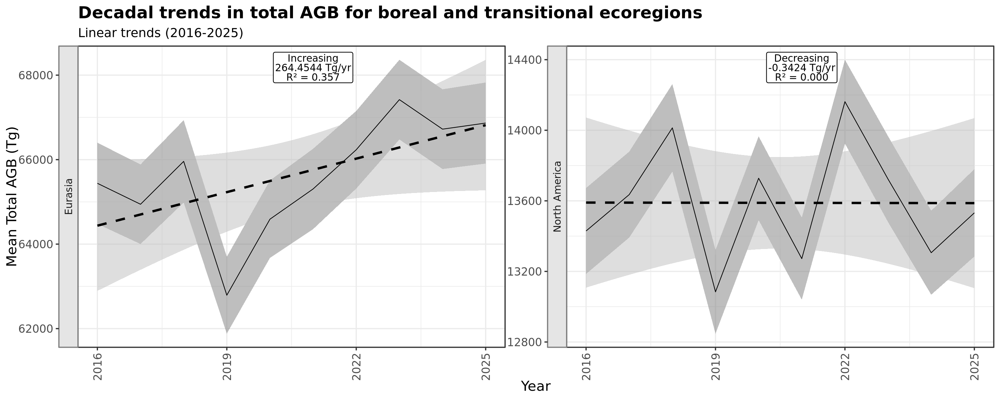

In [719]:
options(repr.plot.width = 10, repr.plot.height = 4, repr.plot.res = 300)

p_realms_timeseries_trend <- ggplot(plot_data_realm,
                            aes(x = year, y = mean_total_AGB_Tg, 
                                group = realm)) +
    geom_vline(xintercept = which(levels(factor(plot_data_realm$year)) == "2019"), 
               linetype = "dashed", alpha = 0.5) +
    
    # Ribbon
    geom_ribbon(aes(ymin = mean_total_AGB_Tg - sd_total_AGB_Tg,
                    ymax = mean_total_AGB_Tg + sd_total_AGB_Tg,
                    fill = realm),
                alpha = 0.5) +

    # Add linear trend line first (behind other elements)
    geom_smooth(aes(color = realm), 
                method = "lm", 
                se = TRUE,
                alpha = 0.5, color='black', fill='gray',
                linetype = "dashed",
                size = 0.8) +
    
    # Line and points with color by biome
    #geom_line(aes(color = biome_name), size = 1) +
    geom_line(color = 'black', size = 0.25) +
    #geom_point(aes(fill = biome_name), shape=21, color='black') +
    # geom_point(aes(size = year == 2019, alpha = year == 2019), color='black') +

    # # Highlight 2019 points with red border
    # geom_point(data = plot_data %>% filter(year == 2019),
    #            aes(group = eco_name),
    #            color = "indianred", size = 4, shape = 21, stroke = 1.5, fill = NA) +

    # Option 3: Color-coded by trend direction with significance
    geom_label(data = trend_stats_realms %>%
                        mutate(
                        facet_label = paste0(realm),
                        combined_label = paste0(trend_direction, "\n", slope_label, "\n", r2_label),
                        #label_color = ifelse(p_value < 0.05, "red", "red")
                       ) %>%
                 arrange(realm) %>%
                 mutate(facet_label = factor(facet_label, 
                                            levels = unique(.$facet_label))),
               aes(x = 2021, y = Inf, label = combined_label
                   #, color = label_color
                  ),
               vjust = 1.2, hjust = 0.5,
               size = 2.5,
               fill = "white",
               alpha = 1,
               label.padding = unit(0.15, "lines"),
               lineheight = 0.8,
               show.legend = FALSE,
               inherit.aes = FALSE) +
      #scale_color_identity() + 
    
    # Use same color scheme as first plot
    scale_color_manual(name = "Biome", values = biome_colors) +
    scale_fill_manual(name = "Biome", values = biome_colors) +
    scale_size_manual(values = c("FALSE" = 2, "TRUE" = 3), guide = "none") +
    scale_alpha_manual(values = c("FALSE" = 0.6, "TRUE" = 1), guide = "none") +
    
    labs(
      title = "Decadal trends in total AGB for boreal and transitional ecoregions",
      subtitle = paste0("Linear trends (2016-2025)"),
      x = "Year",
      y = "Mean Total AGB (Tg)"
    ) +
    geom_legend_ecoregion_timeseries +
    geom_theme_ecoregion_timeseries +

  # Adjust coordinates
  coord_cartesian(xlim=c(2016,2025), clip = "off") +
  # Force integer labels on x-axis
  scale_x_continuous(breaks = seq(2016, 2025, by = 3),
                    labels = seq(2016, 2025, by = 3)) +
    # Use facet_grid with labels on the left (y-axis)
    facet_wrap(realm  ~ ., scales = "free_y", switch = "y", ncol=7)
  
  print(p_realms_timeseries_trend)

#EXPORT_PNG_PDF(p_ecoregion_timeseries_trend, OUT_FIGURE_DIR, 'ecoregion_timeseries_AGB_linear_trend', '2016-2025', FIG_DIMS=c(14,16.25), TYPE='plot')

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's fill values.”
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's fill values.”


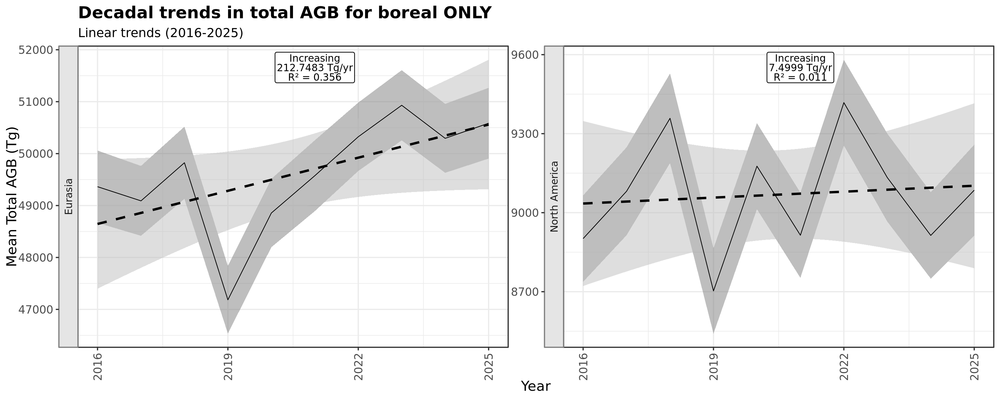

In [725]:
options(repr.plot.width = 10, repr.plot.height = 4, repr.plot.res = 300)

p_boreal_biome_timeseries_trend <- ggplot(plot_data_biomes %>% filter(biome_name == 'Boreal Forests/Taiga'),
                            aes(x = year, y = mean_total_AGB_Tg, 
                                group = realm)) +
    geom_vline(xintercept = which(levels(factor((plot_data_biomes %>% filter(biome_name == 'Boreal Forests/Taiga'))$year)) == "2019"), 
               linetype = "dashed", alpha = 0.5) +
    
    # Ribbon
    geom_ribbon(aes(ymin = mean_total_AGB_Tg - sd_total_AGB_Tg,
                    ymax = mean_total_AGB_Tg + sd_total_AGB_Tg,
                    fill = realm),
                alpha = 0.5) +

    # Add linear trend line first (behind other elements)
    geom_smooth(aes(color = realm), 
                method = "lm", 
                se = TRUE,
                alpha = 0.5, color='black', fill='gray',
                linetype = "dashed",
                size = 0.8) +
    
    # Line and points with color by biome
    #geom_line(aes(color = biome_name), size = 1) +
    geom_line(color = 'black', size = 0.25) +
    #geom_point(aes(fill = biome_name), shape=21, color='black') +
    # geom_point(aes(size = year == 2019, alpha = year == 2019), color='black') +

    # # Highlight 2019 points with red border
    # geom_point(data = plot_data %>% filter(year == 2019),
    #            aes(group = eco_name),
    #            color = "indianred", size = 4, shape = 21, stroke = 1.5, fill = NA) +

    # Option 3: Color-coded by trend direction with significance
    geom_label(data = trend_stats_biome_borealonly %>%
                        mutate(
                        facet_label = paste0(realm),
                        combined_label = paste0(trend_direction, "\n", slope_label, "\n", r2_label),
                        #label_color = ifelse(p_value < 0.05, "red", "red")
                       ) %>%
                 arrange(realm) %>%
                 mutate(facet_label = factor(facet_label, 
                                            levels = unique(.$facet_label))),
               aes(x = 2021, y = Inf, label = combined_label
                   #, color = label_color
                  ),
               vjust = 1.2, hjust = 0.5,
               size = 2.5,
               fill = "white",
               alpha = 1,
               label.padding = unit(0.15, "lines"),
               lineheight = 0.8,
               show.legend = FALSE,
               inherit.aes = FALSE) +
      #scale_color_identity() + 
    
    # Use same color scheme as first plot
    scale_color_manual(name = "Biome", values = biome_colors) +
    scale_fill_manual(name = "Biome", values = biome_colors) +
    scale_size_manual(values = c("FALSE" = 2, "TRUE" = 3), guide = "none") +
    scale_alpha_manual(values = c("FALSE" = 0.6, "TRUE" = 1), guide = "none") +
    
    labs(
      title = "Decadal trends in total AGB for boreal ONLY",
      subtitle = paste0("Linear trends (2016-2025)"),
      x = "Year",
      y = "Mean Total AGB (Tg)"
    ) +
    geom_legend_ecoregion_timeseries +
    geom_theme_ecoregion_timeseries +

  # Adjust coordinates
  coord_cartesian(xlim=c(2016,2025), clip = "off") +
  # Force integer labels on x-axis
  scale_x_continuous(breaks = seq(2016, 2025, by = 3),
                    labels = seq(2016, 2025, by = 3)) +
    # Use facet_grid with labels on the left (y-axis)
    facet_wrap(realm  ~ ., scales = "free_y", switch = "y", ncol=7)
  
  print(p_boreal_biome_timeseries_trend)

#EXPORT_PNG_PDF(p_ecoregion_timeseries_trend, OUT_FIGURE_DIR, 'ecoregion_timeseries_AGB_linear_trend', '2016-2025', FIG_DIMS=c(14,16.25), TYPE='plot')

`geom_smooth()` using formula = 'y ~ x'


/projects/my-public-bucket/boreal_AGBD_trends/paper_figs/plot_ecoregion_timeseries_AGB_linear_trend_2016-2025_20260109.png


`geom_smooth()` using formula = 'y ~ x'


/projects/my-public-bucket/boreal_AGBD_trends/paper_figs/plot_ecoregion_timeseries_AGB_linear_trend_2016-2025_20260109.pdf


`geom_smooth()` using formula = 'y ~ x'


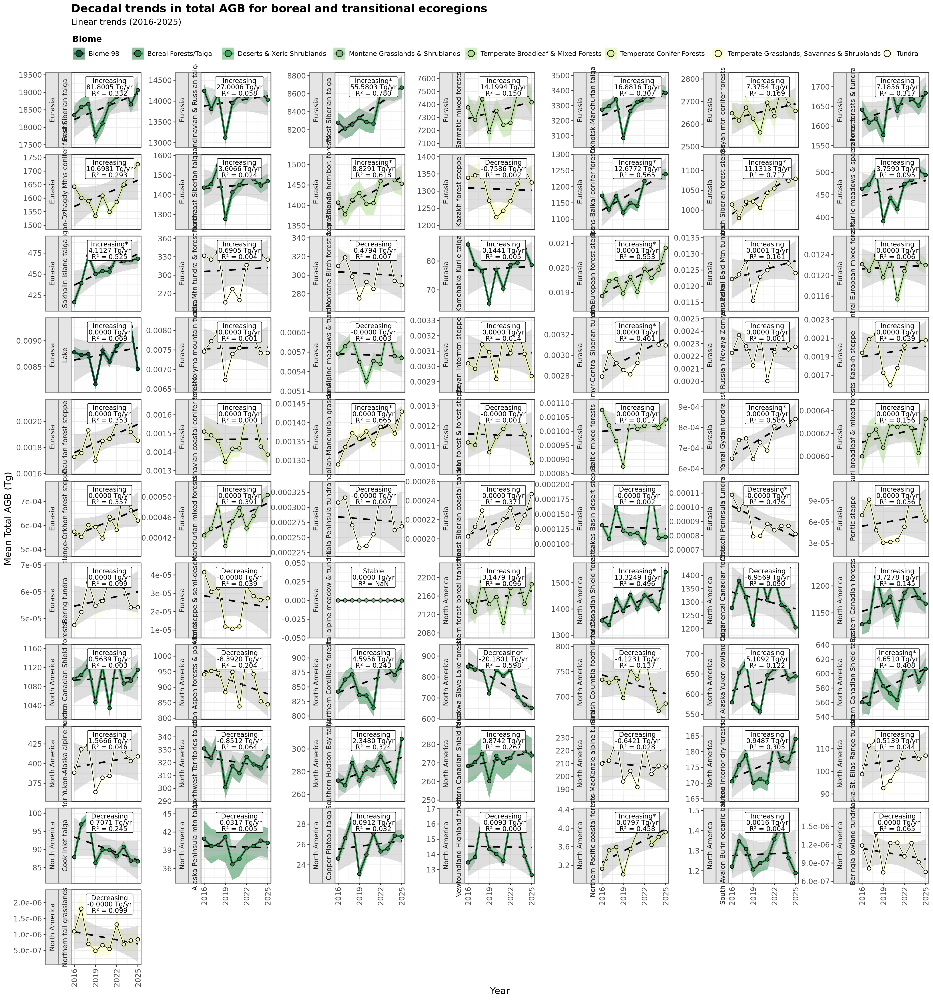

In [715]:
options(repr.plot.width = 14, repr.plot.height = 15, repr.plot.res = 300)

p_ecoregion_timeseries_trend <- ggplot(plot_data_ecoregions,
                            aes(x = year, y = mean_total_AGB_Tg, 
                                group = eco_name)) +
    geom_vline(xintercept = which(levels(factor(plot_data$year)) == "2019"), 
               linetype = "dashed", alpha = 0.5) +
    
    # Ribbon
    geom_ribbon(aes(ymin = mean_total_AGB_Tg - sd_total_AGB_Tg,
                    ymax = mean_total_AGB_Tg + sd_total_AGB_Tg,
                    fill = biome_name),
                alpha = 0.5) +

    # Add linear trend line first (behind other elements)
    geom_smooth(aes(color = biome_name), 
                method = "lm", 
                se = TRUE,
                alpha = 0.5, color='black', fill='gray',
                linetype = "dashed",
                size = 0.8) +
    
    # Line and points with color by biome
    geom_line(aes(color = biome_name), size = 1) +
    geom_line(color = 'black', size = 0.25) +
    geom_point(aes(fill = biome_name), shape=21, color='black') +
    # geom_point(aes(size = year == 2019, alpha = year == 2019), color='black') +

    # # Highlight 2019 points with red border
    # geom_point(data = plot_data %>% filter(year == 2019),
    #            aes(group = eco_name),
    #            color = "indianred", size = 4, shape = 21, stroke = 1.5, fill = NA) +

    # Option 3: Color-coded by trend direction with significance
    geom_label(data = trend_stats_ecoregions %>%
                 mutate(eco_name_abbrev = eco_name %>%
                          str_replace_all("Mountains", "Mtns") %>%
                          str_replace_all(" and ", " & "),
                        facet_label = paste0(realm, "\n", 
                          str_trunc(eco_name_abbrev, width = 35, ellipsis = "...")),
                        combined_label = paste0(trend_direction, "\n", slope_label, "\n", r2_label),
                        #label_color = ifelse(p_value < 0.05, "red", "red")
                       ) %>%
                 arrange(realm, biome_name, eco_name) %>%
                 mutate(facet_label = factor(facet_label, 
                                            levels = unique(.$facet_label))),
               aes(x = 2021, y = Inf, label = combined_label
                   #, color = label_color
                  ),
               vjust = 1.2, hjust = 0.5,
               size = 2.5,
               fill = "white",
               alpha = 1,
               label.padding = unit(0.15, "lines"),
               lineheight = 0.8,
               show.legend = FALSE,
               inherit.aes = FALSE) +
      #scale_color_identity() + 
    
    # Use same color scheme as first plot
    scale_color_manual(name = "Biome", values = biome_colors) +
    scale_fill_manual(name = "Biome", values = biome_colors) +
    scale_size_manual(values = c("FALSE" = 2, "TRUE" = 3), guide = "none") +
    scale_alpha_manual(values = c("FALSE" = 0.6, "TRUE" = 1), guide = "none") +
    
    labs(
      title = "Decadal trends in total AGB for boreal and transitional ecoregions",
      subtitle = paste0("Linear trends (2016-2025)"),
      x = "Year",
      y = "Mean Total AGB (Tg)"
    ) +
    geom_legend_ecoregion_timeseries +
    geom_theme_ecoregion_timeseries +

  # Adjust coordinates
  coord_cartesian(xlim=c(2016,2025), clip = "off") +
  # Force integer labels on x-axis
  scale_x_continuous(breaks = seq(2016, 2025, by = 3),
                    labels = seq(2016, 2025, by = 3)) +
    # Use facet_grid with labels on the left (y-axis)
    facet_wrap(realm + eco_name ~ ., scales = "free_y", switch = "y", ncol=7)
  
  print(p_ecoregion_timeseries_trend)

EXPORT_PNG_PDF(p_ecoregion_timeseries_trend, OUT_FIGURE_DIR, 'ecoregion_timeseries_AGB_linear_trend', '2016-2025', FIG_DIMS=c(14,16.25), TYPE='plot')

#### Explore apparent anomaly in year 2019

In [680]:
# Create the second plot - detailed view of anomalous ecoregions
anomalous_ecoregions <- plot_data_ecoregions %>% 
  filter(has_2019_anomaly) %>% 
  pull(eco_name) %>% 
  unique()

if(length(anomalous_ecoregions) > 0) {
  
  # Prepare data for the anomaly plot with abbreviations
  anomaly_plot_data <- plot_data_ecoregions %>% 
    filter(eco_name %in% anomalous_ecoregions) %>%
    # Create abbreviated ecoregion names
    mutate(
      eco_name_abbrev = eco_name %>%
        str_replace_all("Mountains", "Mtns") 
        #%>% str_replace_all(" and ", "\n& ")
        ,
      # For vertical labels, we can use longer names
      facet_label = paste0(eco_name_abbrev, " [", realm,"]"),
      # Order by realm, then biome, then ecoregion
      facet_order = paste(realm, biome_name, eco_name, sep = "_")
    ) %>%
    arrange(realm, biome_name, eco_name) %>%
    mutate(facet_label = factor(facet_label, levels = unique(facet_label)))
 } 

/projects/my-public-bucket/boreal_AGBD_trends/paper_figs/plot_ecoregion_timeseries_biomes_all_with_2019_anomaly_2016-2025_20260109.png
/projects/my-public-bucket/boreal_AGBD_trends/paper_figs/plot_ecoregion_timeseries_biomes_all_with_2019_anomaly_2016-2025_20260109.pdf


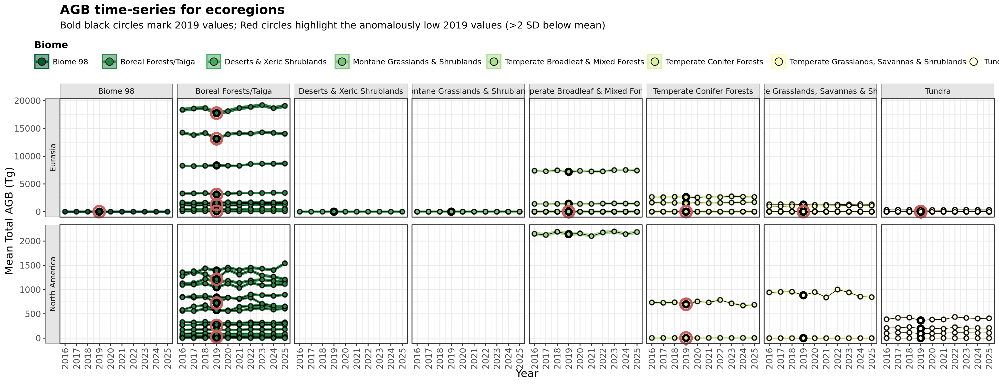

In [681]:
options(repr.plot.width = 13, repr.plot.height = 5, repr.plot.res = 300)

p_ecoregion_timeseries_biomes_all_with_2019_anomaly = ggplot(plot_data_ecoregions, 
                     aes(x = year, y = mean_total_AGB_Tg, 
                         group = eco_name, color = biome_name)) +
    geom_vline(xintercept = which(levels(factor(anomaly_plot_data$year)) == "2019"), 
               linetype = "dashed", alpha = 0.5) +
    
    # Ribbon
    geom_ribbon(aes(ymin = mean_total_AGB_Tg - sd_total_AGB_Tg,
                    ymax = mean_total_AGB_Tg + sd_total_AGB_Tg,
                    fill = biome_name),
                alpha = 0.5) +
    
    # Line and points with color by biome
    geom_line(aes(color = biome_name), size = 1) +
    geom_line(color = 'black', size = 0.25) +
    #geom_point(aes(color = biome_name, size = year == 2019, alpha = year == 2019)) +
    geom_point(aes(size = year == 2019, alpha = year == 2019), color='black') +
    geom_point(aes(fill = biome_name), shape=21, color='black') +

    # Highlight 2019 points with red border
    geom_point(data = anomaly_plot_data %>% filter(year == 2019),
               aes(group = eco_name),
               color = "indianred", size = 4, shape = 21, stroke = 1.5, fill = NA) +
    
    # # Add full ecoregion name as text label inside each facet
    # geom_text(data = anomaly_plot_data %>% 
    #             filter(year == max(year)) %>%
    #             distinct(eco_name, facet_label, .keep_all = TRUE),
    #           aes(x = Inf, y = Inf, label = eco_name_adjusted),
    #           hjust = 1.05, vjust = 1.5,
    #           size = 2.5,
    #           color = "black",
    #           fontface = "italic",
    #           lineheight = 0.8,
    #           inherit.aes = FALSE) +
    
    # Use same color scheme as first plot
  scale_color_manual(name = "Biome", values = biome_colors) +
  scale_fill_manual(name = "Biome", values = biome_colors) +
  scale_size_manual(values = c("FALSE" = 2, "TRUE" = 3), guide = "none") +
    scale_alpha_manual(values = c("FALSE" = 0.6, "TRUE" = 1), guide = "none") +
    
    labs(
      title = "AGB time-series for ecoregions",
      subtitle = sprintf("Bold black circles mark 2019 values; Red circles highlight the anomalously low 2019 values (>%d SD below mean)", SIG_CHANGE_THRESH_SD),
      x = "Year",
      y = "Mean Total AGB (Tg)"
    ) +

    geom_legend_ecoregion_timeseries +
    geom_theme_ecoregion_timeseries +

  # Adjust coordinates
  coord_cartesian(xlim=c(2016,2025), clip = "off") +
  # Force integer labels on x-axis
  scale_x_continuous(breaks = seq(2016, 2025, by = 1),
                    labels = seq(2016, 2025, by = 1)) +
  #expand_limits(x = c(2017, 2025)) + # Extra space for labels
    # Use facet_grid with labels on the left (y-axis)
    facet_grid(realm ~ biome_name, scales = "free_y", switch = "y")

print(p_ecoregion_timeseries_biomes_all_with_2019_anomaly)

EXPORT_PNG_PDF(p_ecoregion_timeseries_biomes_all_with_2019_anomaly, OUT_FIGURE_DIR, 'ecoregion_timeseries_biomes_all_with_2019_anomaly', '2016-2025', FIG_DIMS=c(13,6), TYPE='plot')

/projects/my-public-bucket/boreal_AGBD_trends/paper_figs/plot_ecoregion_timeseries_AGB_2019_anomaly_2016-2025_20260109.png
/projects/my-public-bucket/boreal_AGBD_trends/paper_figs/plot_ecoregion_timeseries_AGB_2019_anomaly_2016-2025_20260109.pdf


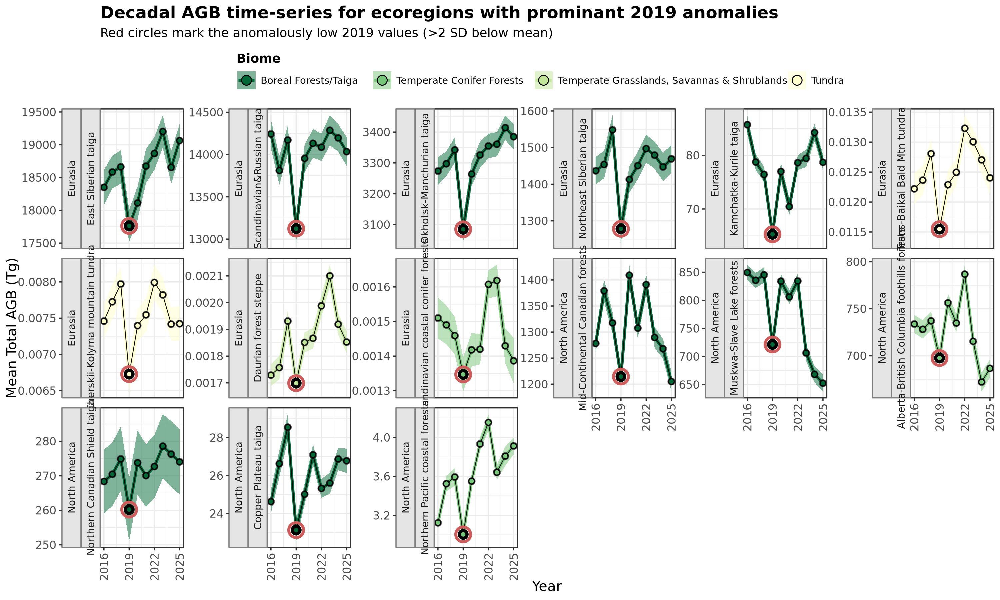

In [529]:
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 300)

p_anomaly_focus <- ggplot(anomaly_plot_data,
                            aes(x = year, y = mean_total_AGB_Tg, 
                                group = eco_name)) +
    geom_vline(xintercept = which(levels(factor(anomaly_plot_data$year)) == "2019"), 
               linetype = "dashed", alpha = 0.5) +
    
    # Ribbon
    geom_ribbon(aes(ymin = mean_total_AGB_Tg - sd_total_AGB_Tg,
                    ymax = mean_total_AGB_Tg + sd_total_AGB_Tg,
                    fill = biome_name),
                alpha = 0.5) +
    
    # Line and points with color by biome
    geom_line(aes(color = biome_name), size = 1) +
    geom_line(color = 'black', size = 0.25) +
    #geom_point(aes(color = biome_name, size = year == 2019, alpha = year == 2019)) +
    geom_point(aes(size = year == 2019, alpha = year == 2019), color='black') +
    geom_point(aes(fill = biome_name), shape=21, color='black') +

    # Highlight 2019 points with red border
    geom_point(data = anomaly_plot_data %>% filter(year == 2019),
               aes(group = eco_name),
               color = "indianred", size = 4, shape = 21, stroke = 1.5, fill = NA) +

    # # Add full ecoregion name as text label inside each facet
    # geom_text(data = anomaly_plot_data %>% 
    #             filter(year == max(year)) %>%
    #             distinct(eco_name, facet_label, .keep_all = TRUE),
    #           aes(x = Inf, y = Inf, label = eco_name_adjusted),
    #           hjust = 1.05, vjust = 1.5,
    #           size = 2.5,
    #           color = "black",
    #           fontface = "italic",
    #           lineheight = 0.8,
    #           inherit.aes = FALSE) +
    
    # Use same color scheme as first plot
  scale_color_manual(name = "Biome", values = biome_colors) +
  scale_fill_manual(name = "Biome", values = biome_colors) +
    scale_size_manual(values = c("FALSE" = 2, "TRUE" = 3), guide = "none") +
    scale_alpha_manual(values = c("FALSE" = 0.6, "TRUE" = 1), guide = "none") +
    
    labs(
      title = "Decadal AGB time-series for ecoregions with prominant 2019 anomalies",
      subtitle = sprintf("Red circles mark the anomalously low 2019 values (>%d SD below mean)", SIG_CHANGE_THRESH_SD),
      x = "Year",
      y = "Mean Total AGB (Tg)"
    ) +
    
    geom_legend_ecoregion_timeseries +
    geom_theme_ecoregion_timeseries + 
    
  # Adjust coordinates
  coord_cartesian(xlim=c(2016,2025), clip = "off") +
  # Force integer labels on x-axis
  scale_x_continuous(breaks = seq(2016, 2025, by = 3),
                    labels = seq(2016, 2025, by = 3)) +
    # Use facet_grid with labels on the left (y-axis)
    facet_wrap(realm + eco_name ~ ., scales = "free_y", switch = "y", ncol=6)
  
  print(p_anomaly_focus)

EXPORT_PNG_PDF(p_anomaly_focus, OUT_FIGURE_DIR, 'ecoregion_timeseries_AGB_2019_anomaly', '2016-2025', FIG_DIMS=c(10,6), TYPE='plot')

## Misc: examine HLS availability across time-series

In [194]:
library(dplyr)

# Enhanced HLS sensor dictionary with mission details
create_detailed_hls_dict <- function() {

  # Get today's date and current year
  today <- Sys.Date()
  CURRENT_YEAR <- as.numeric(format(today, "%Y"))
    
  # Detailed sensor information
  sensor_details <- data.frame(
    sensor_key = c("L7_ETM", "L8_OLI", "L9_OLI2", "S2A_MSI", "S2B_MSI"),
    sensor_number = c("L7", "L8", "L9", "S2A", "S2B"),
    sensor_name = c(
      "Landsat 7",
      "Landsat 8",
      "Landsat 9",
      "Sentinel-2A",
      "Sentinel-2B"
    ),
    instrument_name = c(
      "Enhanced Thematic Mapper Plus",
      "Operational Land Imager",
      "Operational Land Imager-2",
      "MultiSpectral Instrument",
      "MultiSpectral Instrument"
    ),
    mission = c("Landsat", "Landsat", "Landsat", "Sentinel-2", "Sentinel-2"),
    launch_year = c(1999, 2013, 2021, 2015, 2017),
    start_year = c(1999, 2013, 2021, 2015, 2017),
    end_year = c(2025, CURRENT_YEAR, CURRENT_YEAR, CURRENT_YEAR, CURRENT_YEAR),  # Adjust as needed
    spatial_resolution = c(30, 30, 30, 10, 10),
    revisit_days = c(16, 16, 16, 10, 10),
    stringsAsFactors = FALSE
  )
  
  # Create full_name by combining sensor_name and instrument_name
  sensor_details$full_name <- paste(sensor_details$sensor_name, 
                                    sensor_details$instrument_name)
  
  # Create year-based dictionary
  years <- 1999:CURRENT_YEAR
  hls_dict <- list()
  
  for(year in years) {
    # Find sensors active in this year
    active_sensors <- sensor_details %>%
      filter(start_year <= year & end_year >= year)
    
    # Separate by mission
    landsat_sensors <- active_sensors %>% filter(mission == "Landsat")
    sentinel_sensors <- active_sensors %>% filter(mission == "Sentinel-2")
    
    hls_dict[[as.character(year)]] <- list(
      year = year,
      total_sensors = nrow(active_sensors),
      landsat_count = nrow(landsat_sensors),
      sentinel_count = nrow(sentinel_sensors),
      sensor_numbers = active_sensors$sensor_number,
      full_name = active_sensors$full_name,
      sensor_name = active_sensors$sensor_name,
      instrument_name = active_sensors$instrument_name,
      landsat_sensors = landsat_sensors$sensor_number,
      sentinel_sensors = sentinel_sensors$sensor_number,
      missions = unique(active_sensors$mission),
      sensor_details = active_sensors
    )
  }
  
  return(hls_dict)
}


# Function to create the most detailed possible data frame
hls_dict_to_detailed_dataframe <- function(hls_dict) {
  
  # Extract all sensor-year combinations with full details
  df <- map_dfr(hls_dict, function(year_data) {
    
    # Get the sensor details for this year
    sensor_details <- year_data$sensor_details
    
    # Add ALL year-specific information to each sensor row
    sensor_details %>%
      mutate(
        # Year information
        active_year = year_data$year,
        
        # Summary counts for this year
        total_sensors_this_year = year_data$total_sensors,
        landsat_count_this_year = year_data$landsat_count,
        sentinel_count_this_year = year_data$sentinel_count,
        
        # All missions active this year (as comma-separated string)
        all_missions_this_year = paste(year_data$missions, collapse = ", "),
        
        # All sensor numbers active this year (as comma-separated string)
        all_sensors_this_year = paste(year_data$sensor_numbers, collapse = ", "),
        
        # Derived/calculated fields
        years_since_launch = active_year - launch_year,
        sensor_age = active_year - start_year,
        is_landsat = mission == "Landsat",
        is_sentinel = mission == "Sentinel-2",
        
        # Sensor status in this year
        is_first_year = active_year == start_year,
        is_last_year = active_year == end_year
      )
  })
  
  return(df)
}
# Create enhanced dictionary
hls_detailed_dict <- create_detailed_hls_dict()

# Print detailed summary
print_hls_summary <- function(hls_dict) {
  cat("=== DETAILED HLS SENSOR AVAILABILITY ===\n\n")
  
  for(year_str in names(hls_dict)) {
    year_data <- hls_dict[[year_str]]
    
    cat(sprintf("Year %s:\n", year_data$year))
    cat(sprintf("  Total sensors: %d\n", year_data$total_sensors))
    cat(sprintf("  Landsat sensors: %d (%s)\n", 
                year_data$landsat_count, 
                paste(year_data$landsat_sensors, collapse = ", ")))
    cat(sprintf("  Sentinel-2 sensors: %d (%s)\n", 
                year_data$sentinel_count, 
                paste(year_data$sentinel_sensors, collapse = ", ")))
    cat(sprintf("  Missions: %s\n", paste(year_data$missions, collapse = ", ")))
    cat("\n")
  }
}

# Display the summary
print_hls_summary(hls_detailed_dict)

=== DETAILED HLS SENSOR AVAILABILITY ===

Year 1999:
  Total sensors: 1
  Landsat sensors: 1 (L7)
  Sentinel-2 sensors: 0 ()
  Missions: Landsat

Year 2000:
  Total sensors: 1
  Landsat sensors: 1 (L7)
  Sentinel-2 sensors: 0 ()
  Missions: Landsat

Year 2001:
  Total sensors: 1
  Landsat sensors: 1 (L7)
  Sentinel-2 sensors: 0 ()
  Missions: Landsat

Year 2002:
  Total sensors: 1
  Landsat sensors: 1 (L7)
  Sentinel-2 sensors: 0 ()
  Missions: Landsat

Year 2003:
  Total sensors: 1
  Landsat sensors: 1 (L7)
  Sentinel-2 sensors: 0 ()
  Missions: Landsat

Year 2004:
  Total sensors: 1
  Landsat sensors: 1 (L7)
  Sentinel-2 sensors: 0 ()
  Missions: Landsat

Year 2005:
  Total sensors: 1
  Landsat sensors: 1 (L7)
  Sentinel-2 sensors: 0 ()
  Missions: Landsat

Year 2006:
  Total sensors: 1
  Landsat sensors: 1 (L7)
  Sentinel-2 sensors: 0 ()
  Missions: Landsat

Year 2007:
  Total sensors: 1
  Landsat sensors: 1 (L7)
  Sentinel-2 sensors: 0 ()
  Missions: Landsat

Year 2008:
  Total sen

In [190]:
# Simple copy-paste dictionary for HLS sensors by year
create_copy_paste_hls_dict <- function() {
  
  # Generate the dictionary
  hls_dict <- create_detailed_hls_dict()
  
  cat("=== COPY-PASTE HLS SENSOR DICTIONARY ===\n")
  cat("# HLS sensor availability by year\n")
  cat("# Generated on:", as.character(Sys.Date()), "\n\n")
  
  cat("hls_sensor_dict <- list(\n")
  
  years <- names(hls_dict)
  for(i in seq_along(years)) {
    year_str <- years[i]
    year_data <- hls_dict[[year_str]]
    
    cat(sprintf('  "%s" = list(\n', year_str))
    cat(sprintf('    year = %s,\n', year_data$year))
    cat(sprintf('    sensor_count = %d,\n', year_data$total_sensors))
    cat(sprintf('    sensor_numbers = c(%s),\n', 
                paste0('"', year_data$sensor_numbers, '"', collapse = ", ")))
    cat(sprintf('    sensor_names = c(%s),\n', 
                paste0('"', year_data$sensor_names, '"', collapse = ",\n                     ")))
    cat(sprintf('    landsat_count = %d,\n', year_data$landsat_count))
    cat(sprintf('    sentinel_count = %d\n', year_data$sentinel_count))
    
    # Add comma except for last entry
    comma <- if(i < length(years)) "," else ""
    cat(sprintf('  )%s\n', comma))
  }
  
  cat(")\n\n")
  
  # Add helper functions
  cat("# Helper functions\n")
  cat("get_sensors_for_year <- function(year) {\n")
  cat("  return(hls_sensor_dict[[as.character(year)]])\n")
  cat("}\n\n")
  
  cat("get_sensor_count_for_year <- function(year) {\n")
  cat("  year_data <- hls_sensor_dict[[as.character(year)]]\n")
  cat("  return(if(is.null(year_data)) 0 else year_data$sensor_count)\n")
  cat("}\n\n")
  
  cat("# Example usage:\n")
  cat("# sensors_2020 <- get_sensors_for_year(2020)\n")
  cat("# count_2020 <- get_sensor_count_for_year(2020)\n")
}

# Generate copy-paste version
create_copy_paste_hls_dict()

=== COPY-PASTE HLS SENSOR DICTIONARY ===
# HLS sensor availability by year
# Generated on: 2026-01-08 

hls_sensor_dict <- list(
  "1999" = list(
    year = 1999,
    sensor_count = 1,
    sensor_numbers = c("L7"),
    sensor_names = c("Landsat 7 Enhanced Thematic Mapper Plus"),
    landsat_count = 1,
    sentinel_count = 0
  ),
  "2000" = list(
    year = 2000,
    sensor_count = 1,
    sensor_numbers = c("L7"),
    sensor_names = c("Landsat 7 Enhanced Thematic Mapper Plus"),
    landsat_count = 1,
    sentinel_count = 0
  ),
  "2001" = list(
    year = 2001,
    sensor_count = 1,
    sensor_numbers = c("L7"),
    sensor_names = c("Landsat 7 Enhanced Thematic Mapper Plus"),
    landsat_count = 1,
    sentinel_count = 0
  ),
  "2002" = list(
    year = 2002,
    sensor_count = 1,
    sensor_numbers = c("L7"),
    sensor_names = c("Landsat 7 Enhanced Thematic Mapper Plus"),
    landsat_count = 1,
    sentinel_count = 0
  ),
  "2003" = list(
    year = 2003,
    sensor_count = 1,
    sen

In [195]:
hls_dict = create_detailed_hls_dict()

In [196]:
hls_detailed_df = hls_dict_to_detailed_dataframe(hls_dict)
tail(hls_detailed_df)

,sensor_key,sensor_number,sensor_name,instrument_name,mission,launch_year,start_year,end_year,spatial_resolution,revisit_days,⋯,landsat_count_this_year,sentinel_count_this_year,all_missions_this_year,all_sensors_this_year,years_since_launch,sensor_age,is_landsat,is_sentinel,is_first_year,is_last_year
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<int>,<int>,<chr>,<chr>,<dbl>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>
64,S2A_MSI,S2A,Sentinel-2A,MultiSpectral Instrument,Sentinel-2,2015,2015,2026,10,10,⋯,3,2,"Landsat, Sentinel-2","L7, L8, L9, S2A, S2B",10,10,FALSE,TRUE,FALSE,FALSE
65,S2B_MSI,S2B,Sentinel-2B,MultiSpectral Instrument,Sentinel-2,2017,2017,2026,10,10,⋯,3,2,"Landsat, Sentinel-2","L7, L8, L9, S2A, S2B",8,8,FALSE,TRUE,FALSE,FALSE
66,L8_OLI,L8,Landsat 8,Operational Land Imager,Landsat,2013,2013,2026,30,16,⋯,2,2,"Landsat, Sentinel-2","L8, L9, S2A, S2B",13,13,TRUE,FALSE,FALSE,TRUE
67,L9_OLI2,L9,Landsat 9,Operational Land Imager-2,Landsat,2021,2021,2026,30,16,⋯,2,2,"Landsat, Sentinel-2","L8, L9, S2A, S2B",5,5,TRUE,FALSE,FALSE,TRUE
68,S2A_MSI,S2A,Sentinel-2A,MultiSpectral Instrument,Sentinel-2,2015,2015,2026,10,10,⋯,2,2,"Landsat, Sentinel-2","L8, L9, S2A, S2B",11,11,FALSE,TRUE,FALSE,TRUE
69,S2B_MSI,S2B,Sentinel-2B,MultiSpectral Instrument,Sentinel-2,2017,2017,2026,10,10,⋯,2,2,"Landsat, Sentinel-2","L8, L9, S2A, S2B",9,9,FALSE,TRUE,FALSE,TRUE


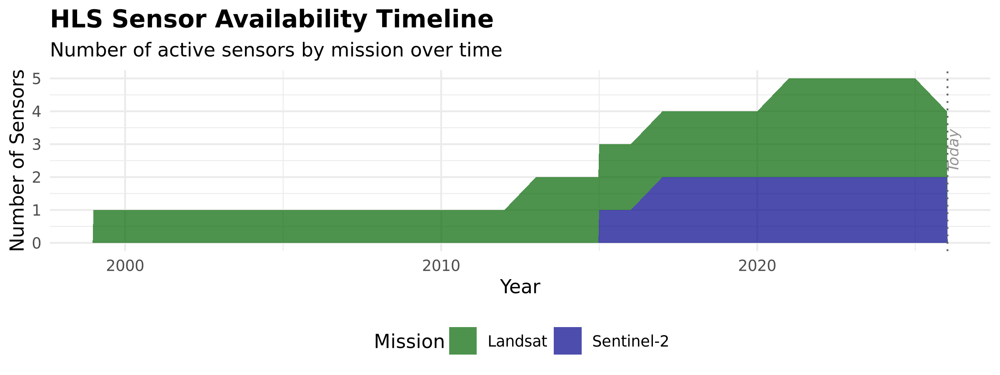

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '◆ = Launch year | Line = Active period' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '◆ = Launch year | Line = Active period' in 'mbcsToSbcs': dot substituted for <97>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '◆ = Launch year | Line = Active period' in 'mbcsToSbcs': dot substituted for <86>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '◆ = Launch year | Line = Active period' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '◆ = Launch year | Line = Active period' in 'mbcsToSbcs': dot substituted for <97>”
Warning message in grid.Call.graphics(C_text, as.

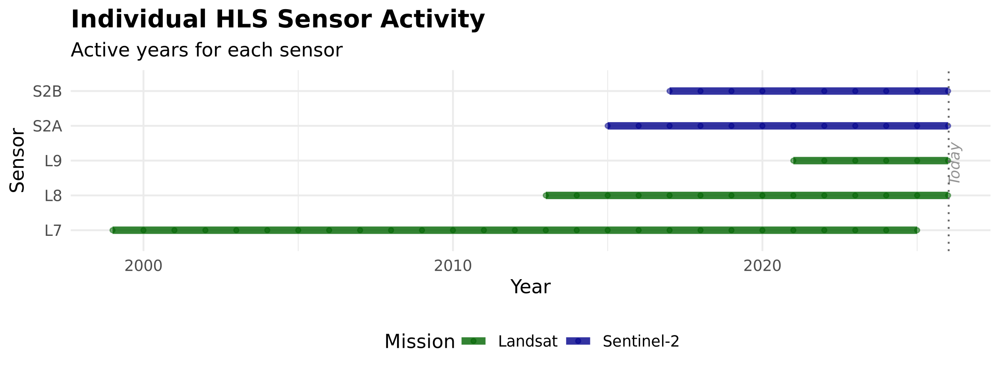

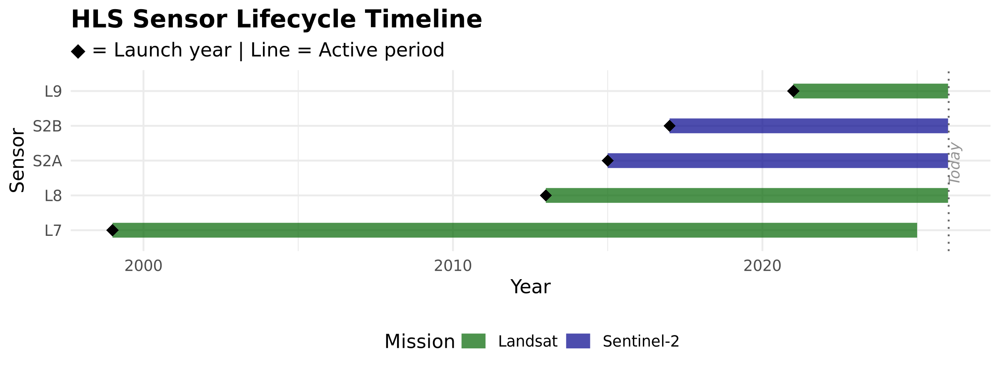

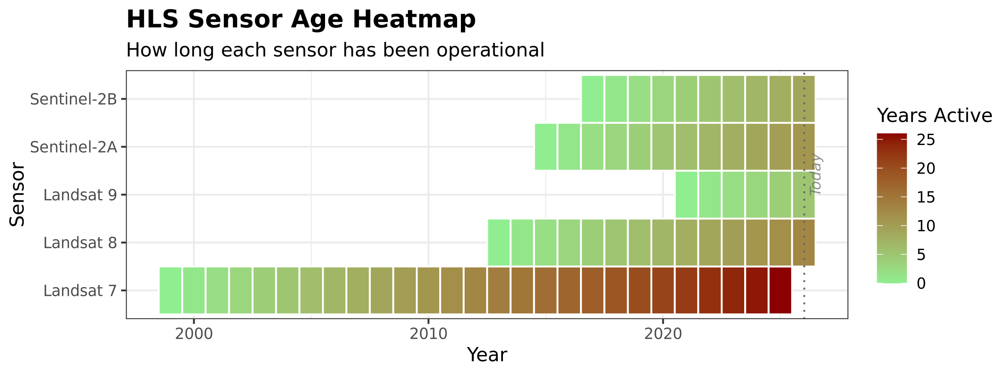

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '◆ = Launch year | Line = Active period' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '◆ = Launch year | Line = Active period' in 'mbcsToSbcs': dot substituted for <97>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '◆ = Launch year | Line = Active period' in 'mbcsToSbcs': dot substituted for <86>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '◆ = Launch year | Line = Active period' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on '◆ = Launch year | Line = Active period' in 'mbcsToSbcs': dot substituted for <97>”
Warning message in grid.Call.graphics(C_text, as.

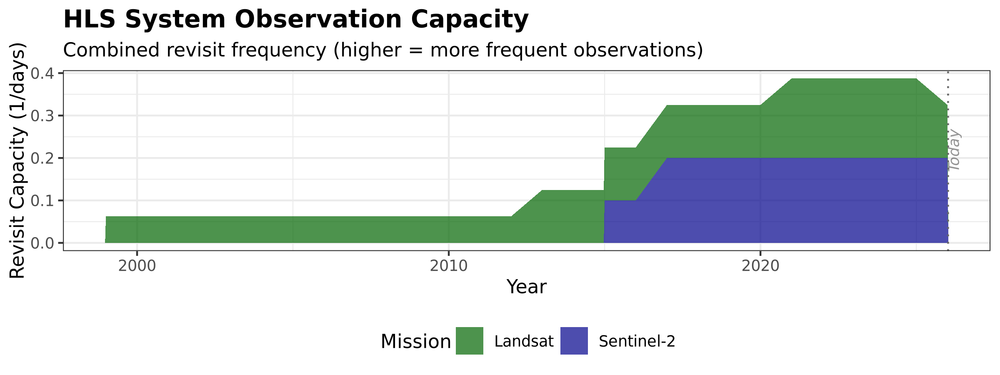

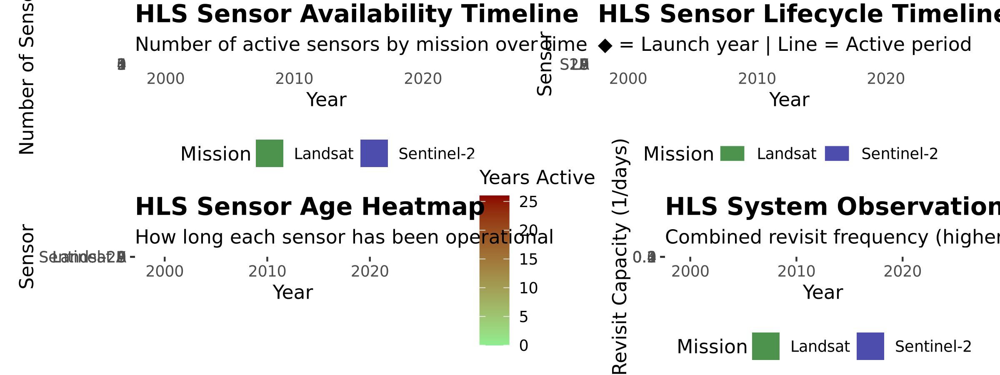

In [202]:
# Function to create detailed HLS sensor timeline visualization
analyze_hls_timeline_detailed <- function(hls_detailed_df) {
  
  # Get today's date as a decimal year
  today <- as.Date(Sys.Date())
  today_year <- as.numeric(format(today, "%Y")) + 
                (as.numeric(format(today, "%j")) - 1) / 365.25
  
  # Create a summary by year and sensor
  timeline_summary <- hls_detailed_df %>%
    group_by(active_year, mission) %>%
    summarise(
      sensor_count = n(),
      .groups = "drop"
    )
  
  # Plot 1: Stacked area chart by mission (original style but with detailed data)
  p1 <- ggplot(timeline_summary, aes(x = active_year, y = sensor_count, fill = mission)) +
    geom_area(alpha = 0.7, position = "stack") +
    geom_vline(xintercept = today_year, linetype = "dotted", color = "gray40", linewidth = 0.5) +
    annotate("text", x = today_year, y = max(tapply(timeline_summary$sensor_count, timeline_summary$active_year, sum)) * 0.95, 
             label = "Today", vjust = 1, hjust = 2, angle = 90, fontface='italic',
             color = "gray40", size = 3, alpha = 0.7) +
    scale_fill_manual(values = c("Landsat" = "darkgreen", "Sentinel-2" = "darkblue")) +
    labs(
      title = "HLS Sensor Availability Timeline",
      subtitle = "Number of active sensors by mission over time",
      x = "Year",
      y = "Number of Sensors",
      fill = "Mission"
    ) +
    theme_minimal() +
    theme(
      plot.title = element_text(size = 14, face = "bold"),
      legend.position = "bottom"
    )
  
  # Plot 2: Individual sensor timelines (NEW - more detailed)
  p2 <- ggplot(hls_detailed_df, aes(x = active_year, y = sensor_number, color = mission)) +
    geom_line(aes(group = sensor_number), linewidth = 2, alpha = 0.8) +
    geom_point(size = 1, alpha = 0.5) +
    geom_vline(xintercept = today_year, linetype = "dotted", color = "gray40", linewidth = 0.5) +
    annotate("text", x = today_year, y = length(unique(hls_detailed_df$sensor_number)) * 0.95, 
             label = "Today", vjust = 1, hjust = 2, angle = 90, fontface='italic',
             color = "gray40", size = 3, alpha = 0.7) +
    scale_color_manual(values = c("Landsat" = "darkgreen", "Sentinel-2" = "darkblue")) +
    labs(
      title = "Individual HLS Sensor Activity",
      subtitle = "Active years for each sensor",
      x = "Year",
      y = "Sensor",
      color = "Mission"
    ) +
    theme_minimal() +
    theme(
      plot.title = element_text(size = 14, face = "bold"),
      legend.position = "bottom"
    )
  
  # Plot 3: Sensor lifecycle view with launch markers (NEW)
  lifecycle_df <- hls_detailed_df %>%
    group_by(sensor_number, full_name, mission, launch_year, start_year, end_year) %>%
    summarise(.groups = "drop")
  
  p3 <- ggplot(lifecycle_df, aes(y = reorder(sensor_number, launch_year))) +
    geom_segment(aes(x = start_year, xend = end_year, yend = sensor_number, color = mission),
                 linewidth = 4, alpha = 0.7) +
    geom_point(aes(x = launch_year), size = 3, shape = 18) +  # Launch marker
    geom_vline(xintercept = today_year, linetype = "dotted", color = "gray40", linewidth = 0.5) +
    annotate("text", x = today_year, y = nrow(lifecycle_df) * 0.95, 
             label = "Today", vjust = 1, hjust = 2, angle = 90, fontface='italic',
             color = "gray40", size = 3, alpha = 0.7) +
    scale_color_manual(values = c("Landsat" = "darkgreen", "Sentinel-2" = "darkblue")) +
    labs(
      title = "HLS Sensor Lifecycle Timeline",
      subtitle = "◆ = Launch year | Line = Active period",
      x = "Year",
      y = "Sensor",
      color = "Mission"
    ) +
    theme_minimal() +
    theme(
      plot.title = element_text(size = 14, face = "bold"),
      legend.position = "bottom"
    )
  
  # Plot 4: Heatmap showing sensor age over time (NEW)
  p4 <- ggplot(hls_detailed_df, aes(x = active_year, y = sensor_name, fill = sensor_age)) +
    geom_tile(color = "white", linewidth = 0.5) +
    geom_vline(xintercept = today_year, linetype = "dotted", color = "gray40", linewidth = 0.5) +
    annotate("text", x = today_year, y = length(unique(hls_detailed_df$sensor_number)) * 0.95, 
             label = "Today", vjust = 1.5, hjust = 2, angle = 90, fontface='italic',
             color = "gray40", size = 3, alpha = 0.7) +
    scale_fill_gradient(low = "lightgreen", high = "darkred", name = "Years Active") +
    labs(
      title = "HLS Sensor Age Heatmap",
      subtitle = "How long each sensor has been operational",
      x = "Year",
      y = "Sensor"
    ) +
    theme_bw() +
    theme(
      plot.title = element_text(size = 14, face = "bold"),
      legend.position = "right"
    )
  
  # Plot 5: Combined capacity view (NEW)
  capacity_df <- hls_detailed_df %>%
    group_by(active_year, mission) %>%
    summarise(
      total_revisit_capacity = sum(1/revisit_days),  # Combined revisit frequency
      avg_resolution = mean(spatial_resolution),
      sensor_count = n(),
      .groups = "drop"
    )
  
  p5 <- ggplot(capacity_df, aes(x = active_year, y = total_revisit_capacity, fill = mission)) +
    geom_area(alpha = 0.7, position = "stack") +
    geom_vline(xintercept = today_year, linetype = "dotted", color = "gray40", linewidth = 0.5) +
    annotate("text", x = today_year, y = max(tapply(capacity_df$total_revisit_capacity, capacity_df$active_year, sum)) * 0.95, 
             label = "Today", vjust = 1, hjust = 2, angle = 90, fontface='italic',
             color = "gray40", size = 3, alpha = 0.7) +
    scale_fill_manual(values = c("Landsat" = "darkgreen", "Sentinel-2" = "darkblue")) +
    labs(
      title = "HLS System Observation Capacity",
      subtitle = "Combined revisit frequency (higher = more frequent observations)",
      x = "Year",
      y = "Revisit Capacity (1/days)",
      fill = "Mission"
    ) +
    theme_bw() +
    theme(
      plot.title = element_text(size = 14, face = "bold"),
      legend.position = "bottom"
    )
  
  # Return all plots in a list
  return(list(
    mission_stacked = p1,
    sensor_lines = p2,
    lifecycle = p3,
    age_heatmap = p4,
    capacity = p5
  ))
}

# Usage:
plots <- analyze_hls_timeline_detailed(hls_detailed_df)

# Display individual plots
print(plots$mission_stacked)   # Original style
print(plots$sensor_lines)       # Individual sensors
print(plots$lifecycle)          # Lifecycle view
print(plots$age_heatmap)        # Age heatmap
print(plots$capacity)           # Observation capacity

# Or use patchwork to combine them
library(patchwork)
(plots$mission_stacked | plots$lifecycle) / 
(plots$age_heatmap | plots$capacity)

#### Get all tiles delivered to DAAC for this project

In [6]:
boreal_tile_DAAC_path = '/projects/shared-buckets/montesano/databank/daac/v3.0/boreal_tiles_v004_AGB_H30_2020_ORNLDAAC.gpkg'
boreal_tiles_gcs_DAAC = st_read(boreal_tile_DAAC_path) %>% st_transform(4326)
boreal_tile_num_DAAC_list =  boreal_tiles_gcs_DAAC %>% as.data.frame() %>% dplyr::select(tile_num) %>% as.list()
boreal_tile_num_DAAC_list = unlist(boreal_tile_num_DAAC_list[[1]])
length(boreal_tile_num_DAAC_list)

Reading layer `boreal_tiles_v004_AGB_H30_2020_ORNLDAAC' from data source 
  `/projects/shared-buckets/montesano/databank/daac/v3.0/boreal_tiles_v004_AGB_H30_2020_ORNLDAAC.gpkg' 
  using driver `GPKG'
Simple feature collection with 3902 features and 3 fields
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: 43.75195 xmax: 180 ymax: 78.53133
Geodetic CRS:  WGS 84


[1] 3902